# Semantic Segmentation of Aerial Imagery

**Students:** Laura-Vanesa Lungu | Filip-Luca Fuciuc  
**Dataset:** [LandCover.ai](https://arxiv.org/abs/2005.02264)  

---

### Project Overview

Semantic segmentation is a computer vision task that aims to classify **every pixel** in an image. For aerial imagery, this enables detailed mapping of land cover and infrastructure, making it useful for applications such as **urban planning, environmental monitoring, agriculture, disaster response, and autonomous mapping systems**.

In this project, we compare **three deep learning architectures** for semantic segmentation using the **LandCover.ai** dataset, a collection of high-resolution aerial orthophotos covering 216 km² of rural Poland. The dataset contains manually annotated masks for five land cover classes.

---

### Task Definition

Unlike image classification, which assigns a single label to an entire image, semantic segmentation predicts a class for **every individual pixel**, producing a dense segmentation map of the scene.

**Input:** RGB aerial image `(3 × 512 × 512)`  
**Output:** Segmentation mask `(5 × 512 × 512)`, containing one prediction score for each class at every pixel.

Each pixel is assigned to one of the following classes:

| Class      | Index | Description                                  |
| ---------- | ----: | -------------------------------------------- |
| Background |     0 | Fields, grass, pavements, and other surfaces |
| Building   |     1 | Rooftops and visible walls                   |
| Woodland   |     2 | Areas covered by trees                       |
| Water      |     3 | Rivers, lakes, and ponds                     |
| Road       |     4 | Roads, parking lots, and railways            |

---

### Models Evaluated
To investigate the impact of network architecture and transfer learning, we train and compare three segmentation models:

|  | Model                | Encoder    | Pretrained   |
| - | -------------------- | ---------- | ------------ |
| 1 | **Vanilla U-Net**    | Custom CNN | From scratch |
| 2 | **U-Net + ResNet50** | ResNet50   | ImageNet     |
| 3 | **DeepLabV3+**       | ResNet50   | ImageNet     |

All models are trained under identical conditions (same data splits, optimizer, learning rate, and number of epochs) and evaluated using **mean Intersection over Union (mIoU)**, computed as a macro-average across all five classes - meaning each class contributes equally to the final score, regardless of how frequently it appears in the data.

Per-class IoU is also reported for each experiment, allowing a detailed analysis of model performance on rare classes (Building, Road) versus dominant ones (Background, Woodland).

---

**Reference notebooks:**
- [Deep Learning for Spatial Semantic Segmentation](https://www.kaggle.com/code/hardiksoni7614/deep-learning-for-spatial-semantic-segmentation) - base pipeline and U-Net implementation
- [DeepLearning on LandCoverAI](https://www.kaggle.com/code/chrisnick92/deeplearning-on-landcoverai) - multi-model comparison structure



## Section 0: Project Setup & Imports

In [ ]:
!pip install torchviz segmentation-models-pytorch torchmetrics -q

In [ ]:
# Suppress Warnings
import warnings
warnings.filterwarnings('ignore')

# Standard Libraries
import os
import time
import glob
import random
import shutil
import numpy as np
from pathlib import Path

# Visualization
import matplotlib.pyplot as plt
import matplotlib.colors
import matplotlib.patches as mpatches
import seaborn as sns

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
from tqdm import tqdm

# Image Processing
import cv2
import albumentations as A
from albumentations.pytorch import ToTensorV2

# Deep Learning Utilities
import segmentation_models_pytorch as smp # open-source with arhitectures for image segmentation
from torchmetrics import JaccardIndex
from torchviz import make_dot # for graph visualization

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)  # PyTorch CPU
torch.cuda.manual_seed(SEED) # Pytorch GPU

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
print(f'GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None"}')
print(f'Total GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB')

# Global Paths
BASE_PATH = '/kaggle/input/datasets/adrianboguszewski/landcoverai/'
IMGS_DIR = BASE_PATH + 'images/'
MASKS_DIR = BASE_PATH + 'masks/'
OUTPUT_DIR = '/kaggle/working/output/'

# Hyperparameters
IMAGE_SIZE = 512
NUM_CLASSES = 5
BATCH_SIZE = 8
NUM_EPOCHS = 30
LR = 5e-5
PATIENCE = 4
TRAIN_RATIO = 0.6
VAL_RATIO = 0.7

# Class Metadata
CLASS_NAMES = ['Background', 'Building', 'Woodland', 'Water', 'Road']
CLASS_COLORS = ['#000000', '#A9A9A9', '#8B8680', '#D3D3D3', '#FFFFFF']
labels_cmap = matplotlib.colors.ListedColormap(CLASS_COLORS)

print('\nSetup complete!')
print(f'Image size: {IMAGE_SIZE}×{IMAGE_SIZE}')
print(f'Batch size: {BATCH_SIZE}')
print(f'Epochs: {NUM_EPOCHS}')
print(f'LR: {LR}')
print(f'Patience: {PATIENCE}')
print(f'Train ratio: {TRAIN_RATIO}')
print(f'Val ratio: {VAL_RATIO}')

Device: cuda
GPU: Tesla T4
Total GPU Memory: 15.64 GB

Setup complete!
Image size: 512×512
Batch size: 8
Epochs: 30
LR: 5e-05
Patience: 4
Train ratio: 0.6
Val ratio: 0.7


## Section 1: Dataset Overview

### 1.1 Orthophotos and GeoTIFF Format

The dataset consists of **41 high-resolution aerial orthophotos** stored in GeoTIFF format. An **orthophoto** is an aerial image that has been geometrically corrected so that each pixel corresponds to a real-world ground position, removing perspective distortions (unlike standard aerial photos where objects may appear tilted).

A **GeoTIFF** is a standard TIFF image enriched with geospatial metadata (e.g., coordinate system, resolution, and geographic bounds).
In our pipeline, this metadata is not used for training - only pixel values are required.

---

### 1.2 Image Characteristics

| Type            | Count | Resolution  | Approx. Size    |
| --------------- | ----- | ----------- | --------------- |
| High-resolution | 33    | 25 cm/pixel | ~9000 × 9500 px |
| Low-resolution  | 8     | 50 cm/pixel | ~4200 × 4700 px |

At 25 cm/pixel, small objects such as cars and narrow roads are clearly visible, while at 50 cm/pixel fine structures become harder to distinguish.

---

### 1.3 Annotation Protocol

Annotations were created **manually** by a team of annotators using the VGG Image Annotator (VIA) tool, using polygon shapes for areas and polylines for narrow roads (later converted to fixed-thickness polygons). Each tile was reviewed by a second person to ensure quality.

Class definitions (important edge cases):
- **Building:** includes roof + visible walls. Greenhouses excluded.
- **Woodland:** groups of trees only. Single trees and orchards excluded.
- **Water:** flowing and stagnant water. Dry riverbeds and ditches excluded.
- **Road:** all road infrastructure including unpaved roads and railways. Narrow roads annotated as polylines with fixed thickness.
- **Background:** everything else — fields, grass, individual trees, pavements.

### 1.4 Train/Val/Test Split

The authors provide pre-computed split files (`train.txt`, `val.txt`, `test.txt`):

| Split | Tiles | Percentage |
|---|---|---|
| Train | 7,470 | 70% |
| Val | 1,602 | 15% |
| Test | 1,602 | 15% |


The split was performed by **shuffling all tiles randomly** and assigning them to splits by index. This works reliably here because with ~10,000 tiles from 41 geographically diverse images, random shuffling naturally produces balanced distributions across all splits.

**In our experiments**, we use `ratio=0.6` on train and `ratio=0.7` on val to reduce training time, while always evaluating on the **full test set** (ratio=1.0) for unbiased final results.

### 1.5 Class Imbalance

As visualized below, the dataset has a **severe class imbalance**:

| Class | Area | % of pixels |
|---|---|---|
| Background | 125.75 km² | ~58% |
| Woodland | 72.02 km² | ~33% |
| Water | 13.15 km² | ~6% |
| Road | 3.5 km² | ~1.6% |
| Building | 1.85 km² | ~0.8% |

This imbalance has a direct consequence for model training: a naive model that predicts **everything as Background** would achieve ~58% pixel accuracy - without detecting a single building or road. This motivates the use of **Jaccard Loss** instead of standard Cross-Entropy




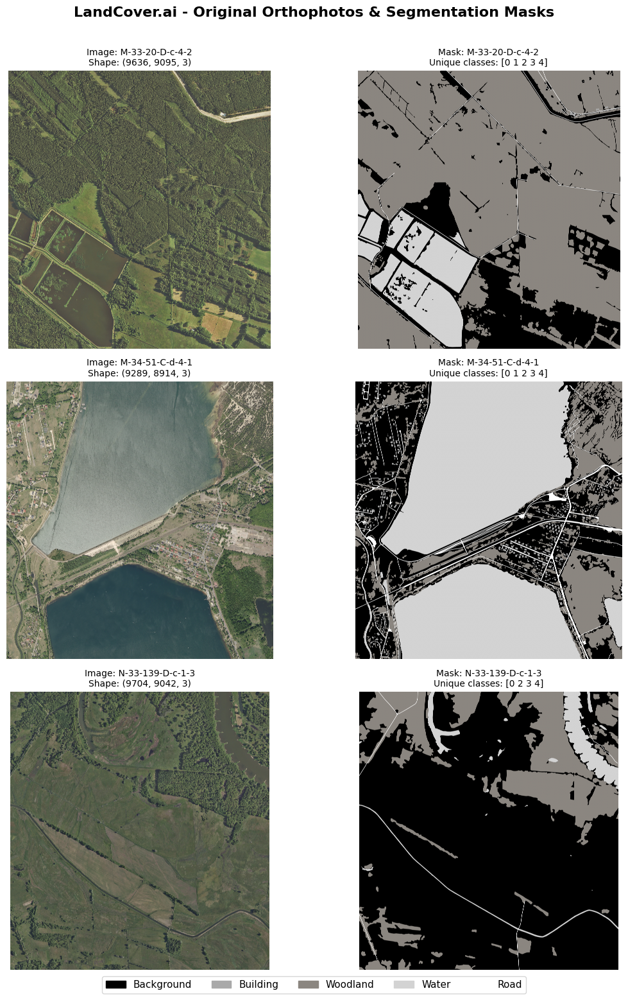

In [ ]:
# Visualize original images + masks

import rasterio # library used for reading geospatial files

def read_tif(path):
    """Read a GeoTIFF file and return as numpy array [H, W, C]."""
    with rasterio.open(path) as src:
        img = src.read() # returns all channels, [C, H, W]
        img = np.transpose(img, (1, 2, 0)) # [H, W, C] - needed for matplotlib and OpenCV
    return img

def read_mask(path):
    """Read a single-channel mask GeoTIFF."""
    with rasterio.open(path) as src:
        mask = src.read(1)  # note that the mask has only one channel! [H, W], values 0-4
    return mask

# Load a few sample images and masks
img_paths  = sorted(glob.glob(os.path.join(IMGS_DIR, '*.tif')))
mask_paths = sorted(glob.glob(os.path.join(MASKS_DIR, '*.tif')))

# Pick 3 samples to display
SAMPLES = [0, 10, 25]

fig, axes = plt.subplots(len(SAMPLES), 2, figsize=(12, 5 * len(SAMPLES)))
fig.suptitle('LandCover.ai - Original Orthophotos & Segmentation Masks',
             fontsize=16, fontweight='bold', y=1.01)

for row, idx in enumerate(SAMPLES):
    img  = read_tif(img_paths[idx])
    mask = read_mask(mask_paths[idx])
    name = Path(img_paths[idx]).stem

    # Image
    axes[row, 0].imshow(img)
    axes[row, 0].set_title(f'Image: {name}\nShape: {img.shape}', fontsize=10)
    axes[row, 0].axis('off')

    # Mask
    axes[row, 1].imshow(mask, cmap=labels_cmap, vmin=0, vmax=4)
    axes[row, 1].set_title(f'Mask: {name}\nUnique classes: {np.unique(mask)}', fontsize=10)
    axes[row, 1].axis('off')

# Legend
legend_patches = [mpatches.Patch(color=CLASS_COLORS[i], label=CLASS_NAMES[i])
                  for i in range(NUM_CLASSES)]
fig.legend(handles=legend_patches, loc='lower center', ncol=5,
           fontsize=11, bbox_to_anchor=(0.5, -0.02))

plt.tight_layout()
plt.show()

Computing class distribution across all masks...

Class Distribution:
Class                 Pixels   Percentage
------------------------------------------
Background     1,735,888,143       58.13%
Building          25,546,030        0.86%
Woodland         994,881,794       33.32%
Water            181,608,253        6.08%
Road              48,340,881        1.62%


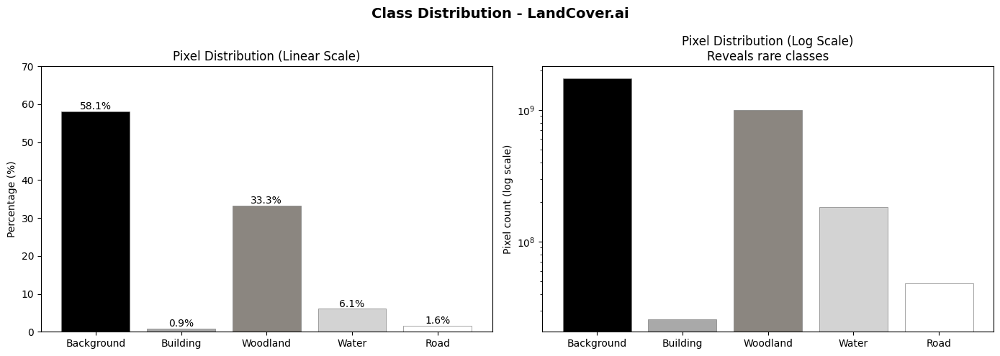

In [ ]:
# Check for Class Distribution

# Count pixels per class across ALL masks
print('Computing class distribution across all masks...')
class_pixel_counts = np.zeros(NUM_CLASSES, dtype=np.int64) #use int64 instead of int32 because we have 41 imgs x 9000x9500px

for mask_path in mask_paths:
    mask = read_mask(mask_path)
    for c in range(NUM_CLASSES):
        class_pixel_counts[c] += np.sum(mask == c)

total_pixels = class_pixel_counts.sum()
class_percentages = class_pixel_counts / total_pixels * 100

# Print table
print('\nClass Distribution:')
print(f'{"Class":<12} {"Pixels":>15} {"Percentage":>12}')
print('-' * 42)
for i, (name, count, pct) in enumerate(zip(CLASS_NAMES, class_pixel_counts, class_percentages)):
    print(f'{name:<12} {count:>15,} {pct:>11.2f}%')

# Bar chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Class Distribution - LandCover.ai', fontsize=14, fontweight='bold')

# Linear scale
axes[0].bar(CLASS_NAMES, class_percentages,color=CLASS_COLORS, edgecolor='gray', linewidth=0.5)
axes[0].set_title('Pixel Distribution (Linear Scale)', fontsize=12)
axes[0].set_ylabel('Percentage (%)')
axes[0].set_ylim(0, 70)
for i, pct in enumerate(class_percentages):
    axes[0].text(i, pct + 0.5, f'{pct:.1f}%', ha='center', fontsize=10)

# Log scale - reveals rare classes - for better visibility
axes[1].bar(CLASS_NAMES, class_pixel_counts,color=CLASS_COLORS, edgecolor='gray', linewidth=0.5)
axes[1].set_yscale('log')
axes[1].set_title('Pixel Distribution (Log Scale)\nReveals rare classes', fontsize=12)
axes[1].set_ylabel('Pixel count (log scale)')

plt.tight_layout()
plt.show()

## Section 2: Data Preprocessing - Tiling

The original orthophotos are extremely large (~9000×9500 px), making them impossible to feed directly into a neural network due to memory constraints. We split them into **512×512pixels tiles**, which is a standard size for semantic segmentation tasks.

### Why 512×512?
- Large enough to capture meaningful context (roads, building clusters, forest patches)
- Small enough to fit multiple tiles in a GPU batch
- Standard size used in the original LandCover.ai paper

### Process
1. Slide a 512×512 window across each image with stride=512 (no overlap)
2. Discard incomplete tiles at the right and bottom edges
3. Save image tiles as `.jpg` and mask tiles as `.png` (lossless image format for masks)
4. Result: ~10,674 tile pairs from 41 original images

### Train/Val/Test split
The authors provide pre-computed `train.txt`, `val.txt`, `test.txt` files listing
which tile belongs to which split - so we use these directly.

In [ ]:
def split_images(imgs_dir, masks_dir, output_dir, target_size=512):
    """
    Split large orthophotos into fixed-size tiles.

    Args:
        imgs_dir: path to original images (.tif)
        masks_dir: path to original masks (.tif)
        output_dir: where to save generated tiles
        target_size: tile size in pixels (default: 512)

    Saves:
        {name}_{k}.jpg   -> image tile (lossy image format, but acceptable for RGB)
        {name}_{k}_m.png -> mask tile  (lossless image format, pixel values 0-4 must remain exact)
    """
    tic = time.time()

    img_paths  = sorted(glob.glob(os.path.join(imgs_dir,  '*.tif')))
    mask_paths = sorted(glob.glob(os.path.join(masks_dir, '*.tif')))

    os.makedirs(output_dir, exist_ok=True)

    for i, (img_path, mask_path) in enumerate(zip(img_paths, mask_paths)):
        img_filename  = os.path.splitext(os.path.basename(img_path))[0]
        mask_filename = os.path.splitext(os.path.basename(mask_path))[0]

        img  = cv2.imread(img_path)
        mask = cv2.imread(mask_path)

        assert img_filename == mask_filename and img.shape[:2] == mask.shape[:2], \
            f"Mismatch: {img_filename} vs {mask_filename}"

        k = 0
        for y in range(0, img.shape[0], target_size):
            for x in range(0, img.shape[1], target_size):
                img_tile  = img[y:y + target_size, x:x + target_size]
                mask_tile = mask[y:y + target_size, x:x + target_size]

                if img_tile.shape[0] == target_size and img_tile.shape[1] == target_size:
                    # gets rid of imcomplete tiles
                    cv2.imwrite(os.path.join(output_dir, f'{img_filename}_{k}.jpg'),   img_tile)
                    cv2.imwrite(os.path.join(output_dir, f'{mask_filename}_{k}_m.png'), mask_tile)
                k += 1

        print(f' {i+1:02d}/{len(img_paths)}] Processed {img_filename}')

    mins, sec = divmod(time.time() - tic, 60)
    n_files = len(os.listdir(output_dir))
    print(f'\nTiling complete in {mins:.0f}m {sec:.2f}s')
    print(f'Generated {n_files} files ({n_files//2} image-mask pairs)')


# Run Tiling (skip if the tile images already exists)

n_existing = len(os.listdir(OUTPUT_DIR)) if os.path.exists(OUTPUT_DIR) else 0

if n_existing >= 21000:  # aprox 21348 files expected
    print(f'Tiles already exist ({n_existing} files). Skipping tiling.')
else:
    print(f'Generating tiles (found only {n_existing} files)...')
    split_images(IMGS_DIR, MASKS_DIR, OUTPUT_DIR, target_size=IMAGE_SIZE)

In [ ]:
# Read authors split files

def read_file_list(txt_path):
    """Read tile names from train.txt / val.txt / test.txt."""
    with open(txt_path, 'r') as f:
        return [line.strip() for line in f.readlines()]

train_files = read_file_list(BASE_PATH + 'train.txt')
val_files   = read_file_list(BASE_PATH + 'val.txt')
test_files  = read_file_list(BASE_PATH + 'test.txt')

print('Split sizes (full dataset):')
print(f'Train: {len(train_files):,} tiles')
print(f'Val: {len(val_files):,} tiles')
print(f'Test: {len(test_files):,} tiles')
print(f'Total: {len(train_files)+len(val_files)+len(test_files):,} tiles')

Split sizes (full dataset):
Train: 7,470 tiles
Val: 1,602 tiles
Test: 1,602 tiles
Total: 10,674 tiles


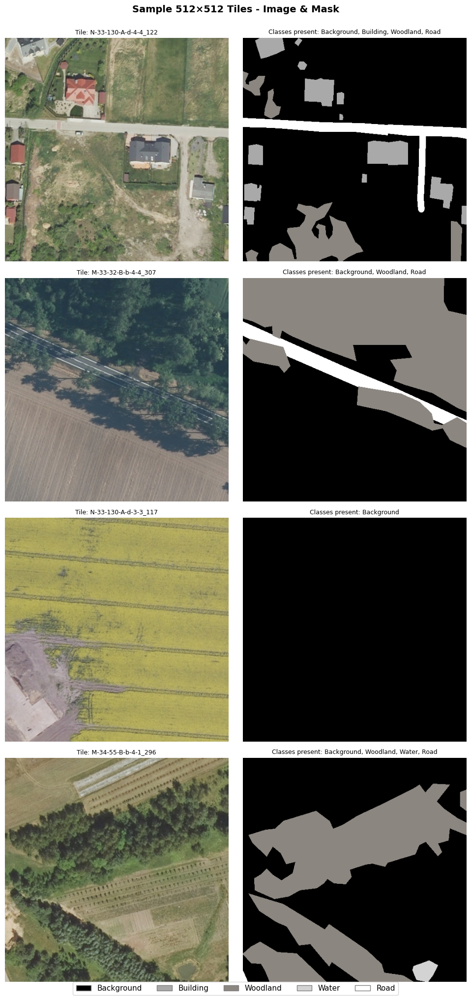

In [ ]:
# Visualize Sample Tiles

# Class color map for mask visualization
CLASS_COLORS_RGB = {
    0: [0,   0,   0  ],  # Background - black
    1: [169, 169, 169],  # Building - gray
    2: [139, 134, 128],  # Woodland - dark gray
    3: [211, 211, 211],  # Water - light gray
    4: [255, 255, 255],  # Road - white
}

def mask_to_rgb(mask_gray):
    """
    Convert single-channel mask (values 0-4) to RGB for visualization.
    Uses the same color scheme as the original paper.
    """
    h, w = mask_gray.shape
    rgb = np.zeros((h, w, 3), dtype=np.uint8)
    for class_idx, color in CLASS_COLORS_RGB.items():
        rgb[mask_gray == class_idx] = color
    return rgb


# Pick 4 random tiles from train set
np.random.seed(SEED)
sample_names = np.random.choice(train_files, 4, replace=False)

fig, axes = plt.subplots(4, 2, figsize=(10, 20))
fig.suptitle('Sample 512×512 Tiles - Image & Mask',
             fontsize=14, fontweight='bold', y = 1.00) # y to lift the title up (to avoid overlapping with the figures)

for row, name in enumerate(sample_names):
    img_path  = os.path.join(OUTPUT_DIR, f'{name}.jpg')
    mask_path = os.path.join(OUTPUT_DIR, f'{name}_m.png')

    img  = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    unique_classes = [CLASS_NAMES[c] for c in np.unique(mask)]

    axes[row, 0].imshow(img)
    axes[row, 0].set_title(f'Tile: {name}', fontsize=9)
    axes[row, 0].axis('off')

    axes[row, 1].imshow(mask_to_rgb(mask))
    axes[row, 1].set_title(f'Classes present: {", ".join(unique_classes)}', fontsize=9)
    axes[row, 1].axis('off')

# Legend
legend_patches = [mpatches.Patch(
    facecolor=[c/255 for c in CLASS_COLORS_RGB[i]],
    edgecolor='gray',
    label=CLASS_NAMES[i]) for i in range(NUM_CLASSES)]
fig.legend(handles=legend_patches, loc='lower center',
           ncol=5, fontsize=11, bbox_to_anchor=(0.5, -0.01))

plt.tight_layout()
plt.show()

## Section 3: Dataset & DataLoader

### 3.1 SegmentationDataset

We implement a custom PyTorch `Dataset` to efficiently load image-mask pairs for semantic segmentation.

The dataset:

* reads file names from predefined splits (`train.txt`, `val.txt`, `test.txt`)
* performs **lazy loading** (images are loaded on demand, not stored in memory)
* applies augmentation (train only) or normalization (val/test)
* returns `(image, mask)` tensors ready for training

Each dataset implements:

* `__init__()`: stores paths and configuration
* `__len__()`: returns dataset size
* `__getitem__()`: loads a single sample

The `DataLoader` uses this interface to build batches efficiently using multiprocessing (`num_workers=2`).

---

### 3.2 Data Augmentation

Applied **only on the training set** to improve generalization by simulating real-world variability in aerial imagery:

| Transform          | Effect                           |
| ------------------ | -------------------------------- |
| HorizontalFlip     | Different flight directions      |
| RandomRotate90     | Camera orientation changes       |
| HueSaturationValue | Seasonal / vegetation variation  |
| BrightnessContrast | Lighting / weather changes       |
| RandomSizedCrop    | Different altitude / zoom levels |

---

### 3.3 Normalization

Two preprocessing strategies are used depending on the model:

**Vanilla U-Net (trained from scratch):**

* pixel values scaled to `[0, 1]` using `x / 255`

**Pretrained models (ResNet50 encoders):**

* ImageNet normalization is applied:  
  ${
  x = \frac{x/255 - \mu}{\sigma}
  }$  
  where
* mean (${\mu}$) = [0.485, 0.456, 0.406]
* std (${\sigma}$)  = [0.229, 0.224, 0.225]

This ensures compatibility with ImageNet-pretrained encoders.

For the experiments with pretrained models a separate dataset class (defined at section 8) is used to avoid double normalization when using Albumentations.

---

### 3.4 Dataset Subsampling

To reduce training time, we use a subset of the dataset:

* Train: 60% of 7,470
* Val: 100% of 1,602
* Test: 100% (1,602 samples, unchanged)

Sampling is random but reproducible (fixed seed) to preserve class distribution.

---

### 3.5 DataLoader

The `DataLoader` handles:

* batching (`batch_size=8`)
* shuffling (training only)
* parallel data loading (`num_workers=2`)

This improves GPU utilization by overlapping data loading with training.

**Output shapes:**

* Images: `[B, 3, 512, 512]`
* Masks: `[B, 512, 512]` (class indices per pixel)


In [ ]:
# Transforms

# Train transforms - with augmentation
train_transform = A.Compose([
    A.OneOf([
        A.HueSaturationValue(hue_shift_limit=40, sat_shift_limit=40,
                             val_shift_limit=30, p=1),
        A.RandomBrightnessContrast(brightness_limit=0.2,
                                   contrast_limit=0.5, p=1),
    ], p=0.5),
    A.OneOf([
        A.RandomRotate90(p=1),
        A.HorizontalFlip(p=1),
        A.RandomSizedCrop(min_max_height=(248, 512),
                          size=(512, 512), p=1),
    ], p=0.5),
])

# Val/Test transforms - no augmentation, no normalization
val_transform = None

In [ ]:
# SegmentationDataset Class

class SegmentationDataset(Dataset):
    """
    Custom PyTorch Dataset for LandCover.ai semantic segmentation.

    Handles:
    - Lazy loading of image-mask pairs from disk
    - Optional random subset via ratio parameter
    - Data augmentation via Albumentations
    - Conversion to PyTorch tensors

    Args:
        file_list: list of tile names (from train/val/test .txt files)
        output_dir: directory containing generated tiles
        transform: Albumentations transform pipeline (optional)
        ratio: fraction of data to use (optional, for faster training)
        seed: random seed for reproducibility
    """
    def __init__(self, file_list, output_dir, transform=None, ratio=None, seed=42):
        if ratio is not None:
            np.random.seed(seed)
            n = int(ratio * len(file_list))
            indices = np.random.choice(len(file_list), n, replace=False)
            self.file_list = [file_list[i] for i in indices]
            print(f' Using {n:,}/{len(file_list):,} tiles (ratio={ratio})')
        else:
            self.file_list = file_list
            print(f' Using all {len(file_list):,} tiles')

        self.output_dir = output_dir
        self.transform  = transform

    def __len__(self):
        return len(self.file_list)

    def __getitem__(self, idx):
        """
        Load one image-mask pair, apply transforms, return tensors.

        Image pipeline: BGR (cv2) -> RGB -> augment -> float32 / 255 -> [C,H,W]
        Mask pipeline: grayscale -> augment -> int64

        Returns:
            img: FloatTensor [3, 512, 512], values in [0, 1]
            mask: LongTensor [512, 512], values in {0,1,2,3,4}
        """
        name = self.file_list[idx]
        img_path = os.path.join(self.output_dir, f'{name}.jpg')
        mask_path = os.path.join(self.output_dir, f'{name}_m.png')

        # Load image (BGR->RGB) and mask (grayscale)
        img  = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        # Apply augmentation (same transform to both image and mask)
        if self.transform:
            augmented = self.transform(image=img, mask=mask)
            img = augmented['image']
            mask = augmented['mask']

        # Convert to tensors
        # img: [H,W,C] uint8 → [C,H,W] float32 / 255 → values in [0,1]
        img = torch.tensor(img, dtype=torch.float32).permute(2, 0, 1) / 255.0
        # mask: [H,W] uint8 -> [H,W] int64 (required by loss functions)
        mask = torch.tensor(mask, dtype=torch.int64)

        return img, mask

In [ ]:
# Instantiate Datasets & DataLoaders

print('Instantiating datasets...')
train_dataset = SegmentationDataset(train_files, OUTPUT_DIR, transform=train_transform, ratio=TRAIN_RATIO)
val_dataset = SegmentationDataset(val_files, OUTPUT_DIR, transform=val_transform)
test_dataset = SegmentationDataset(test_files, OUTPUT_DIR, transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)


print(f'\n Train batches: {len(train_loader):,}')
print(f' Val batches: {len(val_loader):,}')
print(f' Test batches: {len(test_loader):,}')

# Quick shape check
imgs, masks = next(iter(train_loader))
print(f'\nBatch shapes:')
print(f'Images: {imgs.shape} -> [batch, channels, H, W]')
print(f'Masks: {masks.shape} -> [batch, H, W]')
print(f'Image value range: [{imgs.min():.3f}, {imgs.max():.3f}]')
print(f'Mask unique values: {masks.unique().tolist()}')

Instantiating datasets...
 Using 4,482/7,470 tiles (ratio=0.6)
 Using all 1,602 tiles
 Using all 1,602 tiles

 Train batches: 561
 Val batches: 201
 Test batches: 201

Batch shapes:
Images: torch.Size([8, 3, 512, 512]) -> [batch, channels, H, W]
Masks: torch.Size([8, 512, 512]) -> [batch, H, W]
Image value range: [0.000, 1.000]
Mask unique values: [0, 1, 2, 3, 4]


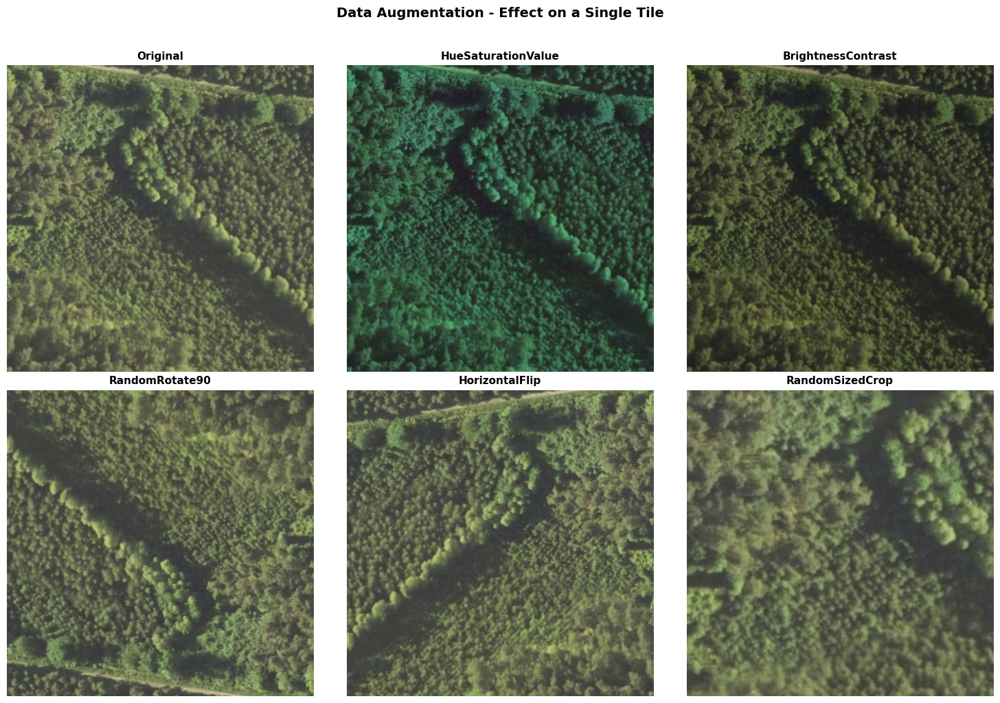

In [ ]:
# Visualize Augmentations

# Show effect of each augmentation individually
individual_transforms = [
    ('Original', None),
    ('HueSaturationValue', A.HueSaturationValue(40, 40, 30, p=1)),
    ('BrightnessContrast', A.RandomBrightnessContrast(0.2, 0.5, p=1)),
    ('RandomRotate90', A.RandomRotate90(p=1)),
    ('HorizontalFlip', A.HorizontalFlip(p=1)),
    ('RandomSizedCrop', A.RandomSizedCrop(min_max_height=(248,512), size=(512,512), p=1)),
]

# Load one sample image
np.random.seed(SEED)
sample_name = train_files[42]
img_raw = cv2.cvtColor(
    cv2.imread(os.path.join(OUTPUT_DIR, f'{sample_name}.jpg')),
    cv2.COLOR_BGR2RGB
)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Data Augmentation - Effect on a Single Tile',
             fontsize=14, fontweight='bold', y=1.02)

for ax, (title, transform) in zip(axes.flatten(), individual_transforms):
    if transform is None:
        result = img_raw
    else:
        result = transform(image=img_raw)['image']
    ax.imshow(result)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()

## Section 4: Experiment 1 - Vanilla U-Net

### 4.1 Architecture Overview

U-Net, proposed by **Ronneberger et al. (2015)**, is one of the most influential architectures for semantic segmentation. Originally developed for biomedical image analysis, it has become a standard baseline for many dense prediction tasks, including aerial image segmentation.

Its success comes from a simple yet effective **encoder–decoder** design:

- **Encoder (contracting path):** progressively extracts higher-level semantic features while reducing spatial resolution.
- **Decoder (expanding path):** gradually reconstructs the original image resolution.
- **Skip connections:** transfer high-resolution features from the encoder directly to the decoder, preserving fine spatial details that would otherwise be lost during downsampling.

<center>

![U-Net Architecture](https://upload.wikimedia.org/wikipedia/commons/2/2b/Example_architecture_of_U-Net_for_producing_k_256-by-256_image_masks_for_a_256-by-256_RGB_image.png)

<!--  -->

<!--  -->



*Original U-Net architecture (Ronneberger et al., 2015). Our implementation follows the same encoder–decoder design with four encoder stages, a bottleneck, four decoder stages, and five output classes.*

</center>

---

### 4.2 Building Blocks

### DoubleConv

The fundamental building block of U-Net is the **DoubleConv** module:

```
Conv (3×3)
↓
BatchNorm
↓
ReLU
↓
Conv (3×3)
↓
BatchNorm
↓
ReLU
```

Using two consecutive **3×3 convolutions** increases the effective receptive field while introducing an additional non-linearity compared to a single convolution. **Batch Normalization** stabilizes training and accelerates convergence, while **ReLU** provides the non-linearity required to learn complex feature representations.

---

### Downsampling (MaxPooling)

The encoder reduces the spatial resolution using **2×2 MaxPooling**.

Each pooling operation halves the image dimensions while preserving the strongest activations:

```
512 × 512
      ↓
256 × 256
      ↓
128 × 128
      ↓
64 × 64
      ↓
32 × 32
```

Reducing the resolution allows the network to learn increasingly abstract and global features.

---

### Upsampling (Transposed Convolution)

The decoder restores the original image resolution using **transposed convolutions** (`ConvTranspose2d`). Unlike fixed interpolation methods, transposed convolutions learn how to upsample feature maps during training.

---

### Skip Connections

Skip connections are the defining feature of U-Net.

At every decoder level, the upsampled feature map is concatenated with the corresponding encoder feature map:

```
Encoder features
        │
        ├──────────────┐
        │              │
        ▼              │
     Decoder ▲         │
        │              │
        └── Concatenate┘
```

They combine:

- **semantic information** learned by the encoder (*what the object is*)
- **high-resolution spatial information** preserved from earlier layers (*where the object is*)

This enables much more accurate object boundaries, particularly for small structures such as buildings and roads.

---

## 4.3 Network Architecture

Our implementation follows the standard U-Net configuration.

| Stage | Resolution | Channels |
|--------|-----------:|---------:|
| Input | 512 × 512 | 3 |
| Encoder 1 | 512 × 512 | 64 |
| Encoder 2 | 256 × 256 | 128 |
| Encoder 3 | 128 × 128 | 256 |
| Encoder 4 | 64 × 64 | 512 |
| Bottleneck | 32 × 32 | 1024 |
| Decoder 4 | 64 × 64 | 512 |
| Decoder 3 | 128 × 128 | 256 |
| Decoder 2 | 256 × 256 | 128 |
| Decoder 1 | 512 × 512 | 64 |
| Output | 512 × 512 | 5 |

The encoder doubles the number of feature channels after every downsampling step, allowing increasingly complex visual patterns to be represented. The decoder mirrors this process by progressively increasing spatial resolution while reducing the number of channels.

---

## 4.4 Output Layer

The final layer is a **1×1 convolution** that converts the 64 decoder features into one prediction score for each semantic class.

Output tensor:

```
[B, 5, 512, 512]
```

where:

- **B** = batch size
- **5** = number of land-cover classes

Each pixel therefore contains **five class scores (logits)**.

During inference, the predicted class is obtained by selecting the channel with the highest score:

```python
prediction = torch.argmax(output, dim=1)
```

producing a segmentation mask of shape:

```
[B, 512, 512]
```

In [ ]:
# DoubleConv Block
class DoubleConv(nn.Module):
    """
    Basic building block of U-Net: Conv→BN→ReLU→Conv→BN→ReLU

    Used in both encoder and decoder at every level.

    Args:
        in_channels: number of input feature maps
        out_channels: number of output feature maps

    Notes:
        - kernel_size=3, padding=1 -> preserves H and W
        - bias=False -> redundant when followed by BatchNorm
          (BN subtracts the mean, canceling any bias)
        - inplace=True in ReLU -> modifies tensor in-place, saves memory
    """
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.conv_block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv_block(x)

In [ ]:
# U-Net Architecture
class UNet(nn.Module):
    """
    Vanilla U-Net for multi-class semantic segmentation.
    Trained from scratch - with no pretrained weights.

    Args:
        in_channels: input channels (3 for RGB)
        out_channels: number of classes (5 for LandCover.ai classes)
        features: channel sizes at each encoder level
        [64, 128, 256, 512] -> standard U-Net

    Encoder channel progression:
        3 -> 64 -> 128 -> 256 -> 512 -> 1024 (bottleneck)

    Decoder channel progression (reversed):
        1024 -> 512 -> 256 -> 128 -> 64 -> 5 (output)

    Spatial resolution progression (512×512 input):
        512 -> 256 -> 128 -> 64 -> 32 (bottleneck)
        32  -> 64  -> 128 -> 256 -> 512 (decoder)
    """
    def __init__(self, in_channels=3, out_channels=5, features=[64, 128, 256, 512]):
        super(UNet, self).__init__()
        self.encoder_blocks = nn.ModuleList()
        self.decoder_blocks = nn.ModuleList()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        # MaxPool 2x2: takes the maximum value in each 2x2 window
        # halves H and W: 512->256->128->64->32

        # ENCODER
        # 4 DoubleConv blocks, channels double at each level
        for feature in features:
            self.encoder_blocks.append(DoubleConv(in_channels, feature))
            in_channels = feature
        # Result: [3->64], [64->128], [128->256], [256->512]

        # BOTTLENECK
        # Deepest point: 32x32, 1024 channels
        # No MaxPool - only DoubleConv increasing channels
        # Contains the most abstract, semantic representation
        self.bottleneck = DoubleConv(features[-1], features[-1] * 2)
        # DoubleConv(512 -> 1024)

        # DECODER
        # Symmetric to encoder, in reverse order
        # Each level: ConvTranspose2d (upsample) + DoubleConv
        for feature in reversed(features):
            self.decoder_blocks.append(nn.ConvTranspose2d(feature * 2, feature, kernel_size=2, stride=2)
                # Learned upsampling: doubles H and W
                # input channels = feature*2 (coming from previous decoder level)
            )
            self.decoder_blocks.append(DoubleConv(feature * 2, feature)
                # input = concat(skip_connection, upsampled)
                # e.g.: concat([B,512,64,64], [B,512,64,64]) = [B,1024,64,64]
                # DoubleConv(1024 -> 512)
            )

        # OUTPUT
        # Conv 1x1: changes only channel count, not H or W
        # 64 channels -> 5 class scores per pixel
        self.output_conv = nn.Conv2d(features[0], out_channels, kernel_size=1)

    def forward(self, x):
        """
        Forward pass through U-Net.

        Input:  [B, 3,  512, 512]
        Output: [B, 5,  512, 512]  - 5 class scores per pixel

        The class with the highest score = predicted class for that pixel.
        Applied via argmax(dim=1) during inference.
        """
        skip_connections = []

        # ENCODING PATH
        for encoder_block in self.encoder_blocks:
            x = encoder_block(x) # DoubleConv: H,W unchanged
            skip_connections.append(x) # save for skip connection
            x = self.pool(x) # MaxPool: H,W halved

        # Dimension trace:
        # [B,3,512,512] =>
        # -> enc1:[B,64,512,512]  -> pool:[B,64,256,256]
        # -> enc2:[B,128,256,256] -> pool:[B,128,128,128]
        # -> enc3:[B,256,128,128] -> pool:[B,256,64,64]
        # -> enc4:[B,512,64,64]   -> pool:[B,512,32,32]

        # BOTTLENECK
        x = self.bottleneck(x)
        # [B,512,32,32] -> [B,1024,32,32]

        # Reverse skip connections for decoder
        # (last encoder output = first decoder input)
        skip_connections = skip_connections[::-1]

        # DECODING PATH
        for idx in range(0, len(self.decoder_blocks), 2):
            # Step 1: upsample (double H and W)
            x = self.decoder_blocks[idx](x)

            # Step 2: get corresponding skip connection
            skip = skip_connections[idx // 2]

            # Step 3: align dimensions if needed (edge cases)
            if x.shape != skip.shape:
                x = TF.resize(x, size=skip.shape[2:])

            # Step 4: concatenate on channel dimension
            # skip: [B,512,64,64] + x: [B,512,64,64] = [B,1024,64,64]
            # combines semantic info (what) + spatial info (where)
            x = torch.cat((skip, x), dim=1)

            # Step 5: DoubleConv on concatenated features
            x = self.decoder_blocks[idx + 1](x)

        # OUTPUT
        return self.output_conv(x)
        # [B,64,512,512] -> [B,5,512,512]


### Multi-GPU Training

When multiple GPUs are available, the model is wrapped with `nn.DataParallel`.
This automatically splits each mini-batch across the available GPUs, performs the forward and backward passes in parallel, and combines the gradients before updating the model. Using two NVIDIA T4 GPUs approximately halves the training time compared to a single GPU.

In [ ]:
# Instantiate Model

model = UNet(in_channels=3, out_channels=NUM_CLASSES)

if torch.cuda.device_count() > 1:
    print(f'Using {torch.cuda.device_count()} GPUs - DataParallel enabled')
    model = nn.DataParallel(model)

model = model.to(device)
# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'  Total parameters: {total_params:,}')
print(f'  Trainable parameters: {trainable_params:,}')
print(f'  Model size (approx): {total_params * 4 / 1e6:.1f} MB')


Using 2 GPUs - DataParallel enabled
  Total parameters: 31,037,893
  Trainable parameters: 31,037,893
  Model size (approx): 124.2 MB


### Computational Graph

The figure below shows the computational graph generated with **torchviz**. Each node represents a differentiable operation performed during the forward pass, while the edges represent the flow of tensors through the network. During backpropagation, PyTorch's **autograd** engine traverses this graph in reverse to compute gradients for every trainable parameter, enabling optimization through gradient descent.

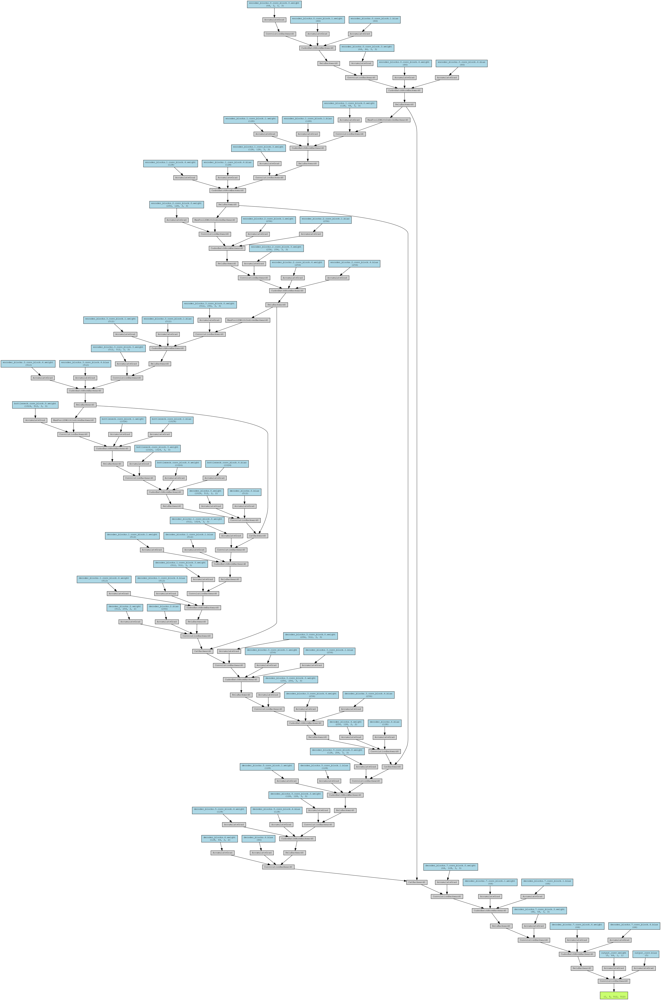

In [ ]:
# Computational Graph (torchviz)
# Use model.module to get the base UNet without DataParallel wrapper
base_model_for_viz = model.module if isinstance(model, nn.DataParallel) else model

dummy_input  = torch.randn(1, 3, 512, 512).to(device)
dummy_output = base_model_for_viz(dummy_input)

dot = make_dot(
    dummy_output,
    params=dict(base_model_for_viz.named_parameters()),
    show_attrs=False,
    show_saved=False
)
dot.attr(rankdir='TB')
dot.attr('node', fontsize='8')
dot.render('/kaggle/working/unet_graph', format='png', cleanup=True)

from IPython.display import Image as IPImage
IPImage('/kaggle/working/unet_graph.png', width=600)

### Training Setup

#### Loss Function - Jaccard Loss

Standard **Cross-Entropy** loss is not suitable for this dataset due to severe
class imbalance. With Cross-Entropy, a model that predicts **everything as Background**
achieves ~58% pixel accuracy - without detecting a single building or road -
because the loss is dominated by the abundant Background pixels.

**Jaccard Loss** (also known as IoU Loss) addresses this directly:

$$\mathcal{L}_{Jaccard} = 1 - IoU =
1 - \frac{|Prediction \cap GroundTruth|}{|Prediction \cup GroundTruth|}$$

Key difference from Cross-Entropy:
- Cross-Entropy: sums loss **per pixel**, rare classes contribute almost nothing
- Jaccard Loss: compares **areas** per class, each class contributes equally regardless of frequency

In multiclass mode (`mode='multiclass'`), Jaccard Loss is computed **independently
per class** and then averaged — so all 5 classes contribute equally to the total loss.

Note: the loss is computed on the **raw model output** (logits `[B, 5, 512, 512]`)
before argmax, making it fully differentiable and usable in backpropagation.

---

#### Evaluation Metric - Jaccard Index (mIoU)

The **Jaccard Index** (also called IoU - Intersection over Union) is the standard
evaluation metric for semantic segmentation:

$$IoU_c = \frac{TP_c}{TP_c + FP_c + FN_c}$$

Where for class $c$:
- $TP_c$ = pixels correctly predicted as class $c$ (True Positives)
- $FP_c$ = pixels incorrectly predicted as class $c$ (False Positives - wrong class predicted)
- $FN_c$ = pixels of class $c$ that were predicted as something else (False Negatives - missed)

The **mean IoU (mIoU)** averages across all classes with equal weight (`average='macro'`):

$$mIoU = \frac{1}{C} \sum_{c=0}^{C-1} IoU_c$$

**Important distinction:** although Jaccard Loss and JaccardIndex share the same
mathematical formula ($1 - IoU$), they serve different roles:

| | `JaccardLoss` | `JaccardIndex` |
|---|---|---|
| **Used for** | Training (backpropagation) | Monitoring & evaluation |
| **Input** | Raw logits `[B, 5, 512, 512]` | Predicted classes `[B, 512, 512]` (after argmax) |
| **When computed** | Every batch | Accumulated over entire val/test set |
| **Differentiable** | Yes (required for `.backward()`) | No (argmax not differentiable) |

During training, we monitor `JaccardIndex` on the validation set after each epoch
as an intuitive measure of progress. During final evaluation, we compute it
separately for each class (`average='none'`) to understand per-class performance,
and as a macro-average (`average='macro'`) for the overall score.

---

#### Early Stopping

Monitors validation loss at the end of each epoch. If the loss does not improve
by at least `min_delta=0.001` for `patience=4` consecutive epochs, training stops
automatically and the best model checkpoint is restored.

This serves two purposes:
- **Prevents overfitting** - stops before the model starts memorizing training data
- **Saves compute** - no need to run all 30 epochs if the model has already converged

The best model weights are saved with `torch.save(state_dict, path)` every time
validation loss improves. With DataParallel, `model.module.state_dict()` is used
to save only the underlying U-Net weights (not the DataParallel wrapper).

---

#### Optimizer — Adam

Adam (Adaptive Moment Estimation) maintains a **per-parameter learning rate**,
adapted using two running estimates:

$$m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t \quad \text{(1st moment - gradient direction)}$$
$$v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2 \quad \text{(2nd moment - gradient variance)}$$
$$\theta_{t+1} = \theta_t - \frac{\eta}{\sqrt{\hat{v}_t} + \epsilon} \hat{m}_t$$

Parameters that receive large, consistent gradients get a **smaller effective
learning rate** (already moving in the right direction). Parameters with small
or noisy gradients get a **larger effective step** (need more encouragement).

We use `lr=5e-5` (0.00005) — a relatively small learning rate, appropriate for
fine-grained pixel-level prediction where aggressive updates could destabilize training.

In [ ]:
# Loss Function

# Jaccard Loss from segmentation_models_pytorch
# mode='multiclass' -> computes IoU per class and averages
# directly optimizes the evaluation metric (mIoU)

loss_fn = smp.losses.JaccardLoss(mode='multiclass')

In [ ]:
# Evaluation Metric

# JaccardIndex = IoU metric (what we optimize AND evaluate with)
# average='macro' -> each class contributes equally (not weighted by frequency)
# !! without macro averaging, rare classes would have minimal impact

metric_fn = JaccardIndex(
    task='multiclass',
    num_classes=NUM_CLASSES,
    average='macro'
).to(device)

In [ ]:
# Early Stopping

class EarlyStopping:
    """
    Monitors validation loss and stops training when no improvement
    is seen for `patience` consecutive epochs.

    Also saves the best model checkpoint automatically -
    ensuring we always keep the best-performing model,
    not just the final one (which may have overfit).

    Args:
        patience: epochs to wait without improvement before stopping
        min_delta: minimum change to qualify as improvement
        checkpoint_path: where to save the best model weights
    """
    def __init__(self, patience=4, min_delta=0.001,
                 checkpoint_path='best_model.pth'):
        self.patience = patience
        self.min_delta = min_delta
        self.checkpoint_path = checkpoint_path
        self.best_loss = float('inf')
        self.counter = 0
        self.early_stop = False

    def __call__(self, val_loss, model):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter   = 0
            # With DataParallel, save model.module.state_dict()
            # model.module = the actual UNet underneath DataParallel wrapper
            state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
            torch.save(state_dict, self.checkpoint_path)
            print(f' Val loss improved -> model saved')
        else:
            self.counter += 1
            print(f' No improvement ({self.counter}/{self.patience})')
            if self.counter >= self.patience:
                self.early_stop = True
                print(f' Early stopping triggered!')

In [ ]:
# Optimizer
optimizer = Adam(model.parameters(), lr=LR)

### Model Training

At each epoch:
1. **Forward pass**: model produces predictions `[B, 5, 512, 512]`
2. **Loss computation**: Jaccard Loss compares predictions with ground truth masks
3. **Backward pass**: PyTorch autograd computes `∂Loss/∂weights` for every parameter
4. **Weight update**: Adam optimizer updates weights using computed gradients


### What we monitor
- **Train Loss**: how well the model fits the training data
- **Val Loss**: how well the model generalizes to unseen data
- **Val mIoU**: mean Intersection over Union across all 5 classes

If Train Loss decreases but Val Loss increases: **overfitting** so Early Stopping triggers.

In [ ]:
# Training Functions

def train_one_epoch(model, loader, optimizer, loss_fn, device):
    """
    Run one full training epoch.

    For each batch:
      1. Forward pass -> predictions [B, 5, 512, 512]
      2. Jaccard Loss -> scalar loss value
      3. Backward pass -> gradients via autograd
      4. Adam optimizer step -> update weights

    Returns:
        avg_loss: average Jaccard Loss over all batches
    """
    model.train()
    total_loss = 0.0

    pbar = tqdm(loader, desc=' Training', leave=False, bar_format='{l_bar}{bar:30}{r_bar}')

    for imgs, masks in pbar:
        imgs = imgs.to(device)
        masks = masks.long().to(device)  # long() required by loss fn

        # 1. Forward pass
        predictions = model(imgs)  # [B, 5, 512, 512]

        # 2. Compute Jaccard Loss
        loss = loss_fn(predictions, masks)

        # 3. Backward pass
        optimizer.zero_grad() # reset gradients from previous batch
        loss.backward() # compute dLoss/dweights for all parameters

        # 4. Update weights
        optimizer.step()

        total_loss += loss.item()
        pbar.set_postfix({'batch_loss': f'{loss.item():.4f}'})

    return total_loss / len(loader)


def validate(model, loader, loss_fn, metric_fn, device):
    """
    Evaluate model on validation set.

    model.eval() + torch.no_grad():
      - Disables dropout
      - BatchNorm uses global running statistics (not per-batch)
      - No gradient computation

    Returns:
        avg_loss: average Jaccard Loss
        avg_iou: mean IoU across all 5 classes (macro average)
    """
    model.eval()
    total_loss = 0.0
    metric_fn.reset()

    with torch.no_grad():
        pbar = tqdm(loader, desc=' Validating', leave=False, bar_format='{l_bar}{bar:30}{r_bar}')

        for imgs, masks in pbar:
            imgs = imgs.to(device)
            masks = masks.long().to(device)

            predictions = model(imgs)
            loss = loss_fn(predictions, masks)
            total_loss += loss.item()

            # argmax -> predicted class per pixel [B, 512, 512]
            pred_classes = predictions.argmax(dim=1)
            metric_fn.update(pred_classes, masks)

    avg_loss = total_loss / len(loader)
    avg_iou = metric_fn.compute().item()
    return avg_loss, avg_iou

In [ ]:
# Full Training Loop
early_stopping = EarlyStopping(
    patience=PATIENCE,
    checkpoint_path='/kaggle/working/unet_vanilla_best.pth'
)

train_losses = []
val_losses = []
val_ious = []

print('  Experiment 1: Vanilla U-Net (trained from scratch)')
print('\n\n')
print(f'  Epochs:      {NUM_EPOCHS}')
print(f'  Batch size:  {BATCH_SIZE}')
print(f'  LR:          {LR}')
print(f'  Train tiles: {len(train_dataset):,}')
print(f'  Val tiles:   {len(val_dataset):,}')

training_start = time.time()

for epoch in range(NUM_EPOCHS):
    epoch_start = time.time()
    print(f'\nEpoch [{epoch+1}/{NUM_EPOCHS}]')

    # Train
    train_loss = train_one_epoch(model, train_loader, optimizer, loss_fn, device)

    # Validate
    val_loss, val_iou = validate(model, val_loader, loss_fn, metric_fn, device)

    # Log
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_ious.append(val_iou)

    epoch_mins, epoch_secs = divmod(time.time() - epoch_start, 60)
    print(f'  Train Loss: {train_loss:.4f}')
    print(f'  Val Loss:   {val_loss:.4f}')
    print(f'  Val mIoU:   {val_iou:.4f}')
    print(f'  Time:       {epoch_mins:.0f}m {epoch_secs:.2f}s')

    # Early stopping check
    early_stopping(val_loss, model)
    if early_stopping.early_stop:
        print(f'\n Training stopped at epoch {epoch+1}')
        break

total_mins, total_secs = divmod(time.time() - training_start, 60)
print('\n' + '=' * 60)
print(f'  Training complete!')
print(f'  Total time:    {total_mins:.0f}m {total_secs:.2f}s')
print(f'  Best Val Loss: {early_stopping.best_loss:.4f}')
print(f'  Epochs run:    {len(train_losses)}')

  Experiment 1: Vanilla U-Net (trained from scratch)



  Epochs:      30
  Batch size:  8
  LR:          5e-05
  Train tiles: 4,482
  Val tiles:   1,602

Epoch [1/30]


  Train Loss: 0.7173
  Val Loss:   0.5718
  Val mIoU:   0.3563
  Time:       11m 57.72s
 Val loss improved -> model saved

Epoch [2/30]


  Train Loss: 0.6462
  Val Loss:   0.5227
  Val mIoU:   0.3863
  Time:       11m 49.15s
 Val loss improved -> model saved

Epoch [3/30]


  Train Loss: 0.5930
  Val Loss:   0.4680
  Val mIoU:   0.4574
  Time:       11m 50.02s
 Val loss improved -> model saved

Epoch [4/30]


  Train Loss: 0.5614
  Val Loss:   0.4460
  Val mIoU:   0.4859
  Time:       11m 51.21s
 Val loss improved -> model saved

Epoch [5/30]


  Train Loss: 0.5343
  Val Loss:   0.3970
  Val mIoU:   0.5557
  Time:       11m 51.21s
 Val loss improved -> model saved

Epoch [6/30]


... (21 outputs left out)

  Train Loss: 0.3405
  Val Loss:   0.2813
  Val mIoU:   0.7328
  Time:       11m 57.59s
 Val loss improved -> model saved

Epoch [28/30]


  Train Loss: 0.3405
  Val Loss:   0.2852
  Val mIoU:   0.7331
  Time:       11m 57.90s
 No improvement (1/4)

Epoch [29/30]


  Train Loss: 0.3345
  Val Loss:   0.2911
  Val mIoU:   0.7064
  Time:       11m 58.99s
 No improvement (2/4)

Epoch [30/30]


  Train Loss: 0.3382
  Val Loss:   0.2754
  Val mIoU:   0.7468
  Time:       11m 57.52s
 Val loss improved -> model saved

  Training complete!
  Total time:    357m 46.33s
  Best Val Loss: 0.2754
  Epochs run:    30


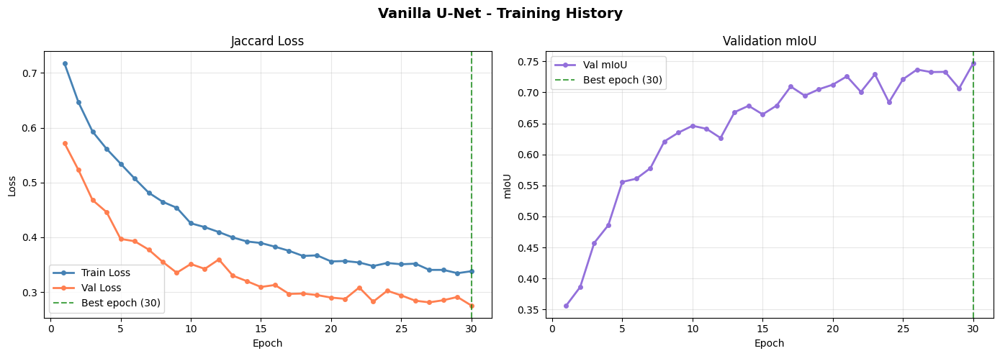

   Best Val Loss: 0.2754 at epoch 30
   Best Val mIoU: 0.7468 at epoch 30


In [ ]:
# Loss & IoU Curves
epochs_ran = range(1, len(train_losses) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Vanilla U-Net - Training History',fontsize=14, fontweight='bold')

# Loss curves
axes[0].plot(epochs_ran, train_losses,label='Train Loss', color='steelblue',linewidth=2, marker='o', markersize=4)
axes[0].plot(epochs_ran, val_losses, label='Val Loss', color='coral', linewidth=2, marker='o', markersize=4)
axes[0].set_title('Jaccard Loss', fontsize=12)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Annotate best val loss
best_epoch = val_losses.index(min(val_losses)) + 1
axes[0].axvline(x=best_epoch, color='green', linestyle='--', alpha=0.7, label=f'Best epoch ({best_epoch})')
axes[0].legend()

# IoU curve
axes[1].plot(epochs_ran, val_ious,label='Val mIoU', color='mediumpurple',linewidth=2, marker='o', markersize=4)
axes[1].set_title('Validation mIoU', fontsize=12)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('mIoU')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Annotate best IoU
best_iou_epoch = val_ious.index(max(val_ious)) + 1
axes[1].axvline(x=best_iou_epoch, color='green',linestyle='--', alpha=0.7,label=f'Best epoch ({best_iou_epoch})')
axes[1].legend()

plt.tight_layout()
plt.savefig('/kaggle/working/unet_vanilla_training_curves.png',dpi=150, bbox_inches='tight')
plt.show()

print(f'   Best Val Loss: {min(val_losses):.4f} at epoch {best_epoch}')
print(f'   Best Val mIoU: {max(val_ious):.4f} at epoch {best_iou_epoch}')

### Evaluation

#### What we evaluate

After training, the **best checkpoint** (lowest validation loss) is loaded and
evaluated on the **full test set** (1,602 tiles, never seen during training or
validation). Three types of analysis are performed:

**1. Per-class IoU and mIoU**  
IoU computed independently for each of the 5 classes, plus the macro-average (mIoU).
This reveals which classes the model handles well and which it struggles with.

**2. Confusion Matrix**

A $5 \times 5$ matrix where:
- **Rows** = ground truth class
- **Columns** = predicted class
- **Diagonal** = correctly classified pixels (TP)
- **Off-diagonal** = misclassifications

The **normalized confusion matrix** (each row divided by its sum) shows the
**recall per class** - what fraction of each true class was correctly identified.
High values off the diagonal reveal systematic confusions.

**3. Visual predictions**
Side-by-side comparison of input image, ground truth mask, and model prediction
for randomly selected test tiles - qualitative assessment of where the model
succeeds and fails.

In [ ]:
# Load Best Model & Evaluate on Test Set

# Load best checkpoint
base_model = UNet(in_channels=3, out_channels=NUM_CLASSES).to(device)
base_model.load_state_dict(
    torch.load('/kaggle/working/unet_vanilla_best.pth', map_location=device)
)
base_model.eval()
model = base_model

# Per-class IoU metric
per_class_iou_fn = JaccardIndex(
    task='multiclass',
    num_classes=NUM_CLASSES,
    average='none'   # returns IoU per class, not averaged
).to(device)

# Overall mIoU metric
overall_iou_fn = JaccardIndex(
    task='multiclass',
    num_classes=NUM_CLASSES,
    average='macro'
).to(device)

# Confusion matrix accumulator
confusion_matrix = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long)

print('Running evaluation on test set...')
tic = time.time()

with torch.no_grad():
    pbar = tqdm(test_loader, desc='  Testing',
                bar_format='{l_bar}{bar:30}{r_bar}')

    for imgs, masks in pbar:
        imgs  = imgs.to(device)
        masks = masks.long().to(device)

        predictions  = model(imgs)
        pred_classes = predictions.argmax(dim=1)  # [B, 512, 512]

        # Update metrics
        per_class_iou_fn.update(pred_classes, masks)
        overall_iou_fn.update(pred_classes, masks)

        # Accumulate confusion matrix
        for pred, gt in zip(pred_classes.cpu(), masks.cpu()):
            for c_true in range(NUM_CLASSES):
                for c_pred in range(NUM_CLASSES):
                    confusion_matrix[c_true, c_pred] += (
                        (gt == c_true) & (pred == c_pred)
                    ).sum().item()

per_class_iou = per_class_iou_fn.compute()
overall_iou = overall_iou_fn.compute().item()

mins, secs = divmod(time.time() - tic, 60)
print(f'Evaluation complete in {mins:.0f}m {secs:.2f}s')

Running evaluation on test set...


  Testing: 100%|██████████████████████████████| 201/201 [03:06<00:00,  1.08it/s]

Evaluation complete in 3m 6.69s


  Vanilla U-Net - Test Set Results
  Class               IoU
--------------------------------------------------
  Background     0.8729   █████████████████
  Building       0.6753   █████████████
  Woodland       0.8488   ████████████████
  Water          0.7783   ███████████████
  Road           0.4969   █████████
--------------------------------------------------
  mIoU           0.7344


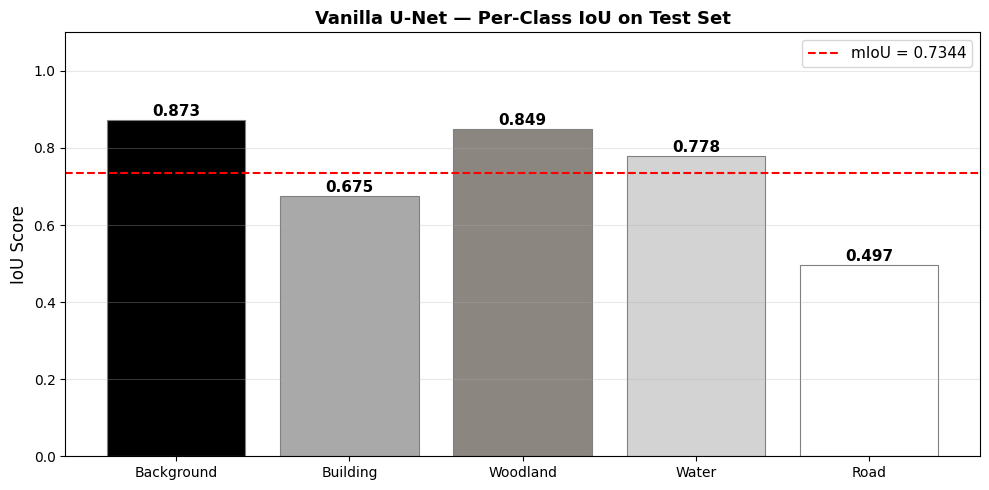

In [ ]:
# Results Table
print('  Vanilla U-Net - Test Set Results')
print(f'  {"Class":<12} {"IoU":>10}')
print('-' * 50)
for i, (name, iou) in enumerate(zip(CLASS_NAMES, per_class_iou)):
    bar = '█' * int(iou.item() * 20)
    print(f'  {name:<12} {iou.item():>8.4f}   {bar}')
print('-' * 50)
print(f'  {"mIoU":<12} {overall_iou:>8.4f}')
print('=' * 50)

# Bar chart per-class IoU
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(CLASS_NAMES,
              [iou.item() for iou in per_class_iou],
              color=CLASS_COLORS, edgecolor='gray', linewidth=0.8)

# Add value labels on bars
for bar, iou in zip(bars, per_class_iou):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.01,
            f'{iou.item():.3f}',
            ha='center', fontsize=11, fontweight='bold')

ax.axhline(y=overall_iou, color='red', linestyle='--',
           linewidth=1.5, label=f'mIoU = {overall_iou:.4f}')
ax.set_ylim(0, 1.1)
ax.set_ylabel('IoU Score', fontsize=12)
ax.set_title('Vanilla U-Net — Per-Class IoU on Test Set',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('/kaggle/working/unet_vanilla_per_class_iou.png',
            dpi=150, bbox_inches='tight')
plt.show()

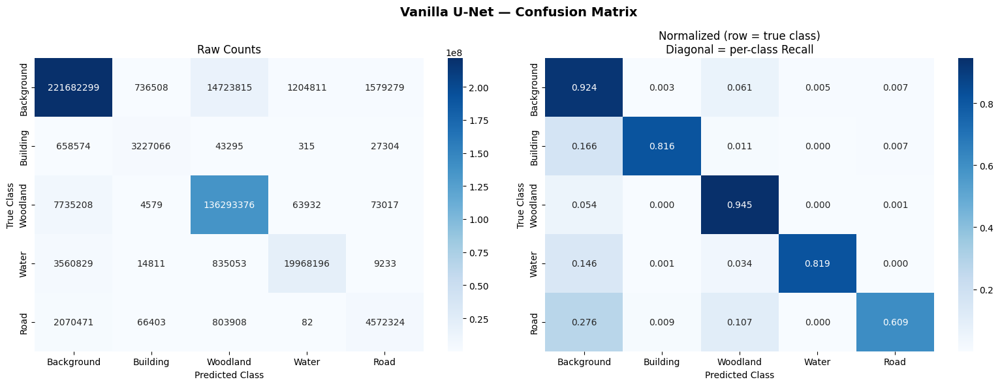

In [ ]:
# Confusion Matrix

# Normalize by row (true class) - shows recall per class
cm_normalized = confusion_matrix.float()
cm_normalized = cm_normalized / cm_normalized.sum(dim=1, keepdim=True).clamp(min=1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Vanilla U-Net — Confusion Matrix',
             fontsize=14, fontweight='bold')

# Raw counts
sns.heatmap(confusion_matrix.numpy(),
            annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES,
            ax=axes[0])
axes[0].set_title('Raw Counts', fontsize=12)
axes[0].set_xlabel('Predicted Class')
axes[0].set_ylabel('True Class')

# Normalized (recall per class)
sns.heatmap(cm_normalized.numpy(),
            annot=True, fmt='.3f', cmap='Blues',
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES,
            ax=axes[1])
axes[1].set_title('Normalized (row = true class)\nDiagonal = per-class Recall',
                  fontsize=12)
axes[1].set_xlabel('Predicted Class')
axes[1].set_ylabel('True Class')

plt.tight_layout()
plt.savefig('/kaggle/working/unet_vanilla_confusion_matrix.png',
            dpi=150, bbox_inches='tight')
plt.show()

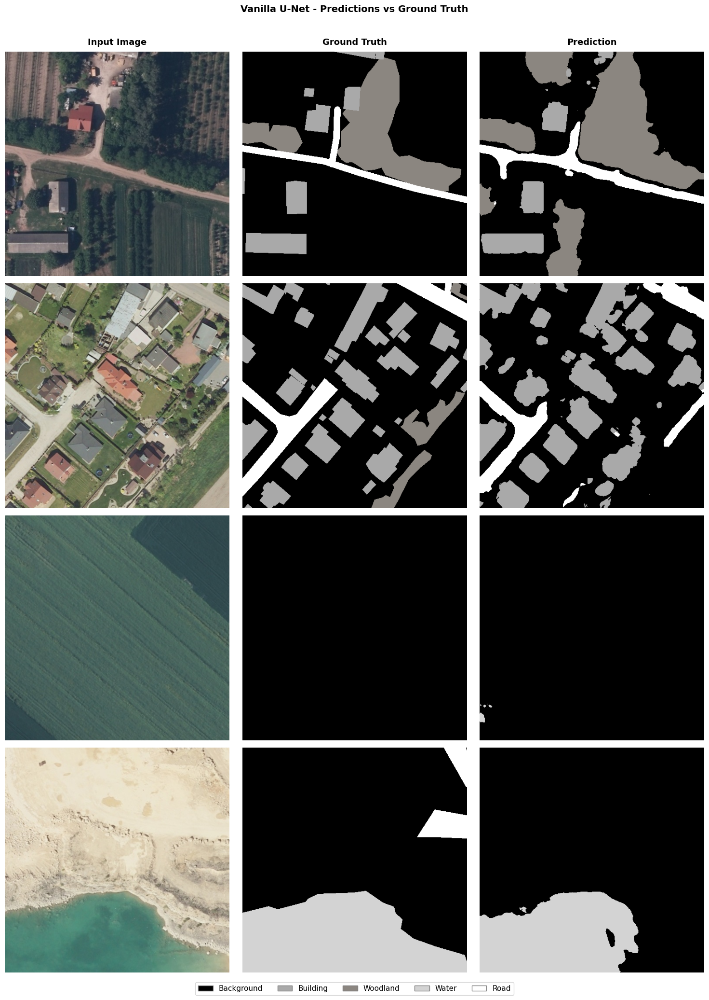

In [ ]:
# Visual Predictions

def visualize_predictions(model, dataset, device, n_samples=4, seed=50):
    """
    Show side-by-side: Input Image | Ground Truth | Prediction
    for n_samples random tiles from the dataset.
    """
    model.eval()
    np.random.seed(seed)
    indices = np.random.choice(len(dataset), n_samples, replace=False)

    fig, axes = plt.subplots(n_samples, 3, figsize=(15, 5 * n_samples))
    fig.suptitle('Vanilla U-Net - Predictions vs Ground Truth',
                 fontsize=14, fontweight='bold', y=1.01)

    col_titles = ['Input Image', 'Ground Truth', 'Prediction']
    for ax, title in zip(axes[0], col_titles):
        ax.set_title(title, fontsize=13, fontweight='bold', pad=10)

    with torch.no_grad():
        for row, idx in enumerate(indices):
            img_tensor, mask_tensor = dataset[idx]

            # Forward pass
            pred = model(img_tensor.unsqueeze(0).to(device))
            pred_class = pred.argmax(dim=1).squeeze(0).cpu().numpy()
            mask_np    = mask_tensor.numpy()

            # Denormalize image for display
            img_np = img_tensor.permute(1, 2, 0).numpy()
            img_np = (img_np * 255).astype(np.uint8)

            # Display
            axes[row, 0].imshow(img_np)
            axes[row, 0].axis('off')

            axes[row, 1].imshow(mask_to_rgb(mask_np))
            axes[row, 1].axis('off')

            axes[row, 2].imshow(mask_to_rgb(pred_class))
            axes[row, 2].axis('off')

    # Legend
    legend_patches = [mpatches.Patch(
        facecolor=[c/255 for c in CLASS_COLORS_RGB[i]],
        edgecolor='gray', label=CLASS_NAMES[i])
        for i in range(NUM_CLASSES)]
    fig.legend(handles=legend_patches, loc='lower center',
               ncol=5, fontsize=11, bbox_to_anchor=(0.5, -0.02))

    plt.tight_layout()
    plt.savefig('/kaggle/working/unet_vanilla_predictions.png',
                dpi=150, bbox_inches='tight')
    plt.show()


visualize_predictions(model, test_dataset, device, n_samples=4)

## Section 5: Experiment 2 – U-Net with ResNet50 Encoder (Transfer Learning)

### 5.1 Motivation

The first experiment used a **Vanilla U-Net**, where both the encoder and decoder were trained from scratch. Although this approach is simple, it requires learning all visual features directly from the LandCover.ai dataset.

In this experiment, we replace the custom encoder with a **ResNet50 pretrained on ImageNet**, while keeping the U-Net decoder. This allows the model to reuse visual representations learned from over one million natural images, reducing the amount of task-specific learning required.

The decoder remains responsible for reconstructing the segmentation map at the original resolution.

<center>

![ResNet U-Net Architecture](https://www.researchgate.net/publication/345841396/figure/fig5/AS:959983546019840@1605889321027/Architecture-of-ResNet-UNet-The-structure-of-the-ResNet-UNet-uses-the-traditional-UNet.png)

*U-Net architecture using a pretrained ResNet50 encoder. The encoder extracts hierarchical features, while the decoder progressively reconstructs the segmentation mask using skip connections.*

</center>

---

### 5.2 Transfer Learning

Instead of initializing all weights randomly, the encoder starts from weights learned on the **ImageNet** dataset.

Transfer learning is based on the observation that the first layers of a convolutional network learn **general-purpose visual features** that are useful across many vision tasks:

- low-level layers detect edges, colors, and simple textures;
- intermediate layers learn shapes and object parts;
- deeper layers capture more semantic structures.

Although ImageNet contains natural images rather than aerial imagery, these low-level representations remain highly transferable.

As a result, the model converges faster and typically achieves better segmentation performance, especially when training data is limited.

---

### 5.3 Why ResNet50?

ResNet50 is a deep convolutional network composed of **residual blocks**.

Instead of learning a direct mapping, each block learns a residual function:

${
y = F(x) + x
}$

where:

- ${F(x)}$ is the learned transformation;
- ${x}$ is an identity shortcut connection.

These residual connections improve gradient propagation through very deep networks, making optimization significantly easier than in traditional CNNs.

Because of its strong feature extraction capabilities, ResNet50 is widely used as a backbone for semantic segmentation models.

---

### 5.4 Architecture

Compared to the Vanilla U-Net, only the **encoder** changes.
The decoder preserves the standard U-Net design by progressively upsampling the feature maps and combining them with encoder features through skip connections.
Only the feature extraction stage benefits from transfer learning.

---

### 5.5 ImageNet Normalization

Since the encoder was pretrained on ImageNet, the input images must be normalized using the same statistics employed during pretraining:

- **Mean:** `[0.485, 0.456, 0.406]`
- **Standard deviation:** `[0.229, 0.224, 0.225]`

The normalization performed by Albumentations is

${
x' = \frac{x/255-\mu}{\sigma}
}$

where ${x}$ represents the original pixel values.

Unlike Experiment 1, the images are **not manually divided by 255**, since `A.Normalize()` already performs both the pixel scaling and the standardization internally.

For this reason, a dedicated `SegmentationDatasetNormalized` class is used for Experiments 2 and 3.

---

### 5.6 Expected Advantages

Replacing the encoder with a pretrained ResNet50 provides several benefits:

- faster convergence during training;
- better feature extraction from the first epochs;
- improved generalization;
- higher segmentation accuracy, particularly for minority classes such as **Buildings** and **Roads**.

The decoder is still trained from scratch, allowing it to adapt specifically to the semantic segmentation task.

### Dataset & Dataloader

In [ ]:
train_transform_resnet = A.Compose([
    A.OneOf([
        A.HueSaturationValue(40, 40, 30, p=1),
        A.RandomBrightnessContrast(0.2, 0.5, p=1),
    ], p=0.5),
    A.OneOf([
        A.RandomRotate90(p=1),
        A.HorizontalFlip(p=1),
        A.RandomSizedCrop(min_max_height=(248, 512),
                          size=(512, 512), p=1),
    ], p=0.5),
    A.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
    # NO ToTensorV2 — SegmentationDatasetNormalized handles conversion manually
])

val_transform_resnet = A.Compose([
    A.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
    # NO ToTensorV2
])

In [ ]:
class SegmentationDatasetNormalized(Dataset):
    """
    Same as SegmentationDataset but WITHOUT /255.0 division.
    Used for pretrained encoder experiments (UNet+ResNet, DeepLabV3+)
    where Albumentations Normalize() handles pixel scaling internally.

    A.Normalize with ImageNet stats:
      output = (input/255 - mean) / std
    So the /255 is already inside the transform — dividing again would corrupt values.
    """
    def __init__(self, file_list, output_dir, transform=None, ratio=None, seed=42):
        if ratio is not None:
            np.random.seed(seed)
            n = int(ratio * len(file_list))
            indices = np.random.choice(len(file_list), n, replace=False)
            self.file_list = [file_list[i] for i in indices]
            print(f'  Using {n:,}/{len(file_list):,} tiles (ratio={ratio})')
        else:
            self.file_list = file_list
            print(f'  Using all {len(file_list):,} tiles')

        self.output_dir = output_dir
        self.transform  = transform

    def __len__(self):
        return len(self.file_list)

    def __getitem__(self, idx):
        name = self.file_list[idx]
        img_path = os.path.join(self.output_dir, f'{name}.jpg')
        mask_path = os.path.join(self.output_dir, f'{name}_m.png')

        img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        if self.transform:
            augmented = self.transform(image=img, mask=mask)
            img = augmented['image']   # numpy [H,W,C] float32, already normalized
            mask = augmented['mask']

        # Permute to [C,H,W] — NO /255.0 (Normalize already handles it)
        img  = torch.tensor(np.array(img), dtype=torch.float32).permute(2, 0, 1)
        mask = torch.tensor(np.array(mask), dtype=torch.int64)

        return img, mask

In [ ]:
# New DataLoaders with ImageNet Normalization

print('Instantiating datasets with ImageNet normalization...')
train_dataset_r = SegmentationDatasetNormalized(
    train_files, OUTPUT_DIR,
    transform=train_transform_resnet,
    ratio=TRAIN_RATIO
)
val_dataset_r = SegmentationDatasetNormalized(
    val_files, OUTPUT_DIR,
    transform=val_transform_resnet
)
test_dataset_r = SegmentationDatasetNormalized(
    test_files, OUTPUT_DIR,
    transform=val_transform_resnet
)

train_loader_r = DataLoader(train_dataset_r, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader_r = DataLoader(val_dataset_r, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader_r = DataLoader(test_dataset_r, batch_size=BATCH_SIZE,shuffle=False, num_workers=2, pin_memory=True)

# Verify shapes
imgs, masks = next(iter(train_loader_r))
print(f'Batch images: {imgs.shape}')
print(f'Batch masks: {masks.shape}')
print(f'Image range: [{imgs.min():.3f}, {imgs.max():.3f}]')

Instantiating datasets with ImageNet normalization...
  Using 4,482/7,470 tiles (ratio=0.6)
  Using 1,121/1,602 tiles (ratio=0.7)
  Using all 1,602 tiles
Batch images: torch.Size([8, 3, 512, 512])
Batch masks: torch.Size([8, 512, 512])
Image range: [-2.118, 2.640]


### Multi-GPU Training

In [ ]:
# Model: U-Net + ResNet50 Encoder

# segmentation_models_pytorch provides ready-made encoder-decoder architectures
# with pretrained encoders from torchvision
model_resnet = smp.Unet(
    encoder_name='resnet50',        # ResNet50 as encoder
    encoder_weights='imagenet',     # pretrained on ImageNet
    in_channels=3,                  # RGB input
    classes=NUM_CLASSES,            # 5 output classes
)

# Enable DataParallel if multiple GPUs available
if torch.cuda.device_count() > 1:
    print(f'Using {torch.cuda.device_count()} GPUs — DataParallel enabled!')
    model_resnet = nn.DataParallel(model_resnet)

model_resnet = model_resnet.to(device)

# Count parameters
total_params     = sum(p.numel() for p in model_resnet.parameters())
trainable_params = sum(p.numel() for p in model_resnet.parameters() if p.requires_grad)

print('\nU-Net + ResNet50 Summary:')
print(f'Total parameters: {total_params:,}')
print(f'Trainable parameters: {trainable_params:,}')
print(f'Model size (approx): {total_params * 4 / 1e6:.1f} MB')

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

Using 2 GPUs — DataParallel enabled!

U-Net + ResNet50 Summary:
Total parameters: 32,521,685
Trainable parameters: 32,521,685
Model size (approx): 130.1 MB


### Training Setup

In [ ]:
# Loss, Metric, Optimizer, EarlyStopping

loss_fn_r = smp.losses.JaccardLoss(mode='multiclass')
metric_fn_r = JaccardIndex(
    task='multiclass',
    num_classes=NUM_CLASSES,
    average='macro'
).to(device)

optimizer_r = Adam(model_resnet.parameters(), lr=LR)

early_stopping_r = EarlyStopping(
    patience=PATIENCE,
    checkpoint_path='/kaggle/working/unet_resnet_best.pth'
)

### Model Training

In [ ]:
# Training - U-Net + ResNet50

train_losses_r = []
val_losses_r = []
val_ious_r = []

print(f'Encoder:     ResNet50 pretrained on ImageNet')
print(f'Epochs:      {NUM_EPOCHS}')
print(f'Batch size:  {BATCH_SIZE}')
print(f'LR:          {LR}')
print(f'Train tiles: {len(train_dataset_r):,}')
print(f'Val tiles:   {len(val_dataset_r):,}')
print('\n')

training_start_r = time.time()

for epoch in range(NUM_EPOCHS):
    epoch_start = time.time()
    print(f'\nEpoch [{epoch+1}/{NUM_EPOCHS}]')

    train_loss = train_one_epoch(
        model_resnet, train_loader_r, optimizer_r, loss_fn_r, device
    )
    val_loss, val_iou = validate(
        model_resnet, val_loader_r, loss_fn_r, metric_fn_r, device
    )

    train_losses_r.append(train_loss)
    val_losses_r.append(val_loss)
    val_ious_r.append(val_iou)

    epoch_mins, epoch_secs = divmod(time.time() - epoch_start, 60)
    print(f'Train Loss: {train_loss:.4f}')
    print(f'Val Loss:   {val_loss:.4f}')
    print(f'Val mIoU:   {val_iou:.4f}')
    print(f'Time:       {epoch_mins:.0f}m {epoch_secs:.2f}s')

    early_stopping_r(val_loss, model_resnet)
    if early_stopping_r.early_stop:
        print(f'\n Early stopping at epoch {epoch+1}')
        break

total_mins_r, total_secs_r = divmod(time.time() - training_start_r, 60)
print('\n' + '=' * 60)
print(f'  Training complete!')
print(f'  Total time:    {total_mins_r:.0f}m {total_secs_r:.2f}s')
print(f'  Best Val Loss: {early_stopping_r.best_loss:.4f}')
print(f'  Epochs run:    {len(train_losses_r)}')
print('=' * 60)

Encoder:     ResNet50 pretrained on ImageNet
Epochs:      30
Batch size:  8
LR:          5e-05
Train tiles: 4,482
Val tiles:   1,121



Epoch [1/30]


Train Loss: 0.6147
Val Loss:   0.4375
Val mIoU:   0.6673
Time:       4m 14.07s
 Val loss improved -> model saved

Epoch [2/30]


Train Loss: 0.4434
Val Loss:   0.3245
Val mIoU:   0.7435
Time:       4m 19.14s
 Val loss improved -> model saved

Epoch [3/30]


Train Loss: 0.3668
Val Loss:   0.2979
Val mIoU:   0.7611
Time:       4m 21.21s
 Val loss improved -> model saved

Epoch [4/30]


Train Loss: 0.3267
Val Loss:   0.2724
Val mIoU:   0.7816
Time:       4m 22.15s
 Val loss improved -> model saved

Epoch [5/30]


Train Loss: 0.3122
Val Loss:   0.2740
Val mIoU:   0.7659
Time:       4m 24.07s
 No improvement (1/4)

Epoch [6/30]


... (9 outputs left out)

Train Loss: 0.2418
Val Loss:   0.2300
Val mIoU:   0.8081
Time:       4m 24.38s
 No improvement (1/4)

Epoch [16/30]


Train Loss: 0.2447
Val Loss:   0.2247
Val mIoU:   0.8133
Time:       4m 25.17s
 No improvement (2/4)

Epoch [17/30]


Train Loss: 0.2442
Val Loss:   0.2289
Val mIoU:   0.8116
Time:       4m 25.53s
 No improvement (3/4)

Epoch [18/30]


Train Loss: 0.2467
Val Loss:   0.2248
Val mIoU:   0.8114
Time:       4m 24.73s
 No improvement (4/4)
 Early stopping triggered!

 Early stopping at epoch 18

  Training complete!
  Total time:    78m 58.53s
  Best Val Loss: 0.2234
  Epochs run:    18


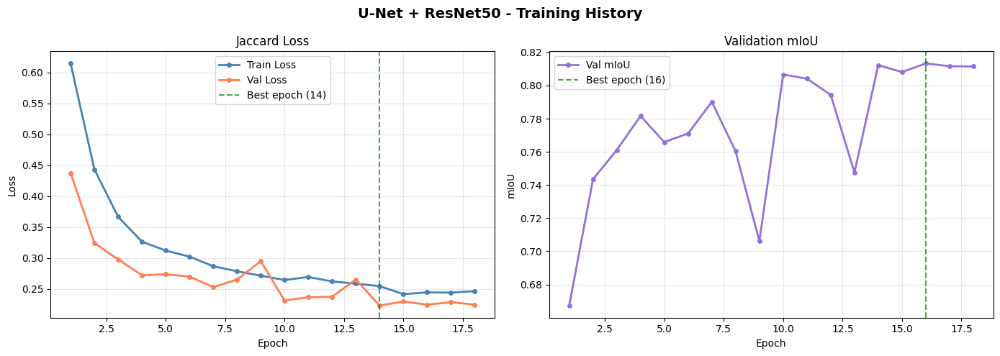

Best Val Loss: 0.2234 at epoch 14
Best Val mIoU: 0.8133 at epoch 16


In [ ]:
# Loss Curves - U-Net + ResNet50
epochs_ran_r = range(1, len(train_losses_r) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('U-Net + ResNet50 - Training History', fontsize=14, fontweight='bold')
axes[0].plot(epochs_ran_r, train_losses_r,label='Train Loss', color='steelblue', linewidth=2, marker='o', markersize=4)
axes[0].plot(epochs_ran_r, val_losses_r, label='Val Loss', color='coral', linewidth=2, marker='o', markersize=4)
axes[0].set_title('Jaccard Loss', fontsize=12)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

best_epoch_r = val_losses_r.index(min(val_losses_r)) + 1
axes[0].axvline(x=best_epoch_r, color='green',linestyle='--', alpha=0.7,label=f'Best epoch ({best_epoch_r})')
axes[0].legend()
axes[1].plot(epochs_ran_r, val_ious_r,label='Val mIoU', color='mediumpurple',linewidth=2, marker='o', markersize=4)
axes[1].set_title('Validation mIoU', fontsize=12)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('mIoU')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

best_iou_epoch_r = val_ious_r.index(max(val_ious_r)) + 1
axes[1].axvline(x=best_iou_epoch_r, color='green',linestyle='--', alpha=0.7,label=f'Best epoch ({best_iou_epoch_r})')
axes[1].legend()

plt.tight_layout()
plt.savefig('/kaggle/working/unet_resnet_training_curves.png',dpi=150, bbox_inches='tight')
plt.show()

print(f'Best Val Loss: {min(val_losses_r):.4f} at epoch {best_epoch_r}')
print(f'Best Val mIoU: {max(val_ious_r):.4f} at epoch {best_iou_epoch_r}')

### Evaluation

In [ ]:
# Evaluation - U-Net + ResNet50

base_model_r = smp.Unet(
    encoder_name='resnet50',
    encoder_weights=None,
    in_channels=3,
    classes=NUM_CLASSES,
).to(device)

base_model_r.load_state_dict(
    torch.load('/kaggle/working/unet_resnet_best.pth', map_location=device)
)
base_model_r.eval()

per_class_iou_fn_r = JaccardIndex(
    task='multiclass',
    num_classes=NUM_CLASSES,
    average='none'
).to(device)

overall_iou_fn_r = JaccardIndex(
    task='multiclass',
    num_classes=NUM_CLASSES,
    average='macro'
).to(device)

confusion_matrix_r = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long)

print('Running evaluation on test set...')
tic = time.time()

with torch.no_grad():
    pbar = tqdm(test_loader_r, desc='  Testing',
                bar_format='{l_bar}{bar:30}{r_bar}')
    for imgs, masks in pbar:
        imgs  = imgs.to(device)
        masks = masks.long().to(device)

        preds        = base_model_r(imgs)
        pred_classes = preds.argmax(dim=1)

        per_class_iou_fn_r.update(pred_classes, masks)
        overall_iou_fn_r.update(pred_classes, masks)

        for pred, gt in zip(pred_classes.cpu(), masks.cpu()):
            for c_true in range(NUM_CLASSES):
                for c_pred in range(NUM_CLASSES):
                    confusion_matrix_r[c_true, c_pred] += (
                        (gt == c_true) & (pred == c_pred)
                    ).sum().item()

per_class_iou_r = per_class_iou_fn_r.compute()
overall_iou_r   = overall_iou_fn_r.compute().item()

mins, secs = divmod(time.time() - tic, 60)
print(f'Evaluation complete in {mins:.0f}m {secs:.2f}s')

# Results table
print('\n' + '=' * 50)
print('  U-Net + ResNet50 — Test Set Results')
print('=' * 50)
print(f'  {"Class":<12} {"IoU":>10}')
print('-' * 50)
for name, iou in zip(CLASS_NAMES, per_class_iou_r):
    bar = '█' * int(iou.item() * 20)
    print(f'  {name:<12} {iou.item():>8.4f}   {bar}')
print('-' * 50)
print(f'  {"mIoU":<12} {overall_iou_r:>8.4f}')
print('=' * 50)

Running evaluation on test set...


  Testing: 100%|██████████████████████████████| 201/201 [01:12<00:00,  2.77it/s]

Evaluation complete in 1m 12.64s

  U-Net + ResNet50 — Test Set Results
  Class               IoU
--------------------------------------------------
  Background     0.9049   ██████████████████
  Building       0.7506   ███████████████
  Woodland       0.8774   █████████████████
  Water          0.8812   █████████████████
  Road           0.5941   ███████████
--------------------------------------------------
  mIoU           0.8016


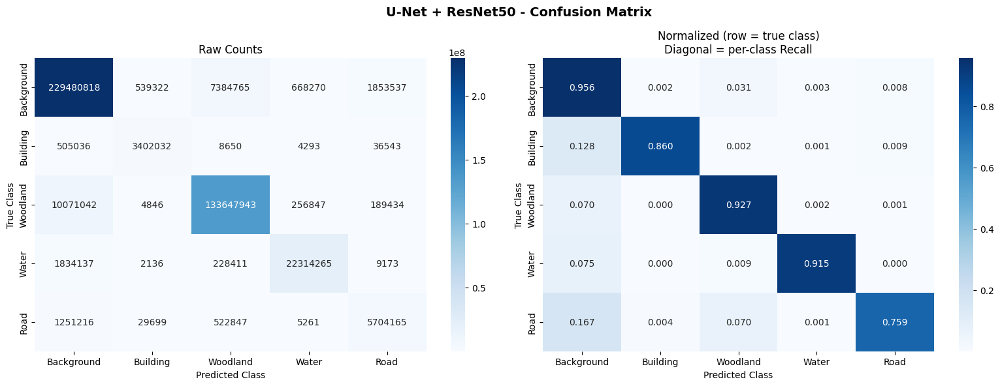

In [ ]:
# Confusion Matrix - U-Net + ResNet50

cm_normalized_r = confusion_matrix_r.float()
cm_normalized_r = cm_normalized_r / cm_normalized_r.sum(dim=1, keepdim=True).clamp(min=1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('U-Net + ResNet50 - Confusion Matrix',
             fontsize=14, fontweight='bold')

sns.heatmap(confusion_matrix_r.numpy(),
            annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES,
            ax=axes[0])
axes[0].set_title('Raw Counts', fontsize=12)
axes[0].set_xlabel('Predicted Class')
axes[0].set_ylabel('True Class')

sns.heatmap(cm_normalized_r.numpy(),
            annot=True, fmt='.3f', cmap='Blues',
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES,
            ax=axes[1])
axes[1].set_title('Normalized (row = true class)\nDiagonal = per-class Recall',
                  fontsize=12)
axes[1].set_xlabel('Predicted Class')
axes[1].set_ylabel('True Class')

plt.tight_layout()
plt.savefig('/kaggle/working/unet_resnet_confusion_matrix.png',
            dpi=150, bbox_inches='tight')
plt.show()

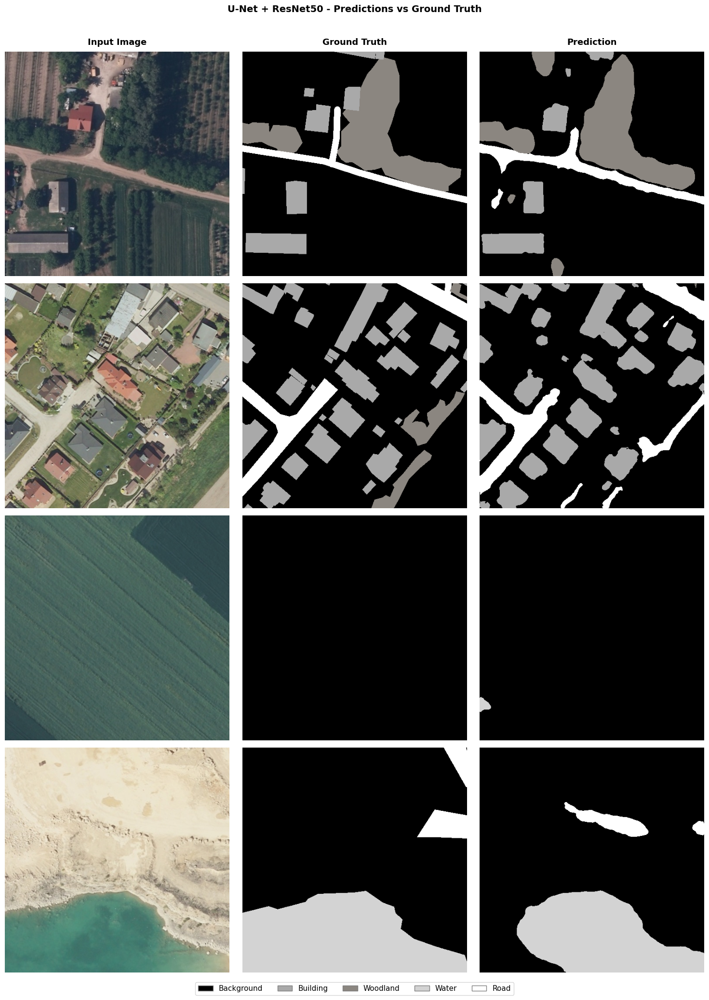

In [ ]:
# Visual Predictions - U-Net + ResNet50

def denormalize_imagenet(tensor):
    """
    Reverse ImageNet normalization for visualization.
    tensor: [C, H, W] normalized with ImageNet stats
    returns: [H, W, C] uint8 in [0, 255]
    """
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    img  = tensor.cpu() * std + mean   # reverse normalization
    img  = img.clamp(0, 1)
    img  = img.permute(1, 2, 0).numpy()
    return (img * 255).astype(np.uint8)


def visualize_predictions_resnet(model, dataset, device, n_samples=4, seed=50):
    """
    Show side-by-side: Input Image | Ground Truth | Prediction
    for U-Net + ResNet50. Uses denormalization for ImageNet-normalized inputs.
    """
    model.eval()
    np.random.seed(seed)
    indices = np.random.choice(len(dataset), n_samples, replace=False)

    fig, axes = plt.subplots(n_samples, 3, figsize=(15, 5 * n_samples))
    fig.suptitle('U-Net + ResNet50 - Predictions vs Ground Truth',
                 fontsize=14, fontweight='bold', y=1.01)

    col_titles = ['Input Image', 'Ground Truth', 'Prediction']
    for ax, title in zip(axes[0], col_titles):
        ax.set_title(title, fontsize=13, fontweight='bold', pad=10)

    with torch.no_grad():
        for row, idx in enumerate(indices):
            img_tensor, mask_tensor = dataset[idx]

            pred = model(img_tensor.unsqueeze(0).to(device))
            pred_class = pred.argmax(dim=1).squeeze(0).cpu().numpy()
            mask_np = mask_tensor.numpy()

            # Denormalize ImageNet normalization for display
            img_np = denormalize_imagenet(img_tensor)

            axes[row, 0].imshow(img_np)
            axes[row, 0].axis('off')

            axes[row, 1].imshow(mask_to_rgb(mask_np))
            axes[row, 1].axis('off')

            axes[row, 2].imshow(mask_to_rgb(pred_class))
            axes[row, 2].axis('off')

    legend_patches = [mpatches.Patch(
        facecolor=[c/255 for c in CLASS_COLORS_RGB[i]],
        edgecolor='gray', label=CLASS_NAMES[i])
        for i in range(NUM_CLASSES)]
    fig.legend(handles=legend_patches, loc='lower center',
               ncol=5, fontsize=11, bbox_to_anchor=(0.5, -0.02))

    plt.tight_layout()
    plt.savefig('/kaggle/working/unet_resnet_predictions.png',
                dpi=150, bbox_inches='tight')
    plt.show()


visualize_predictions_resnet(base_model_r, test_dataset_r, device, n_samples=4)

## Section 6: Experiment 3 - DeepLabV3+

### 6.1 Motivation

The first two experiments used U-Net-based architectures, where the decoder
progressively reconstructs spatial resolution through upsampling and skip connections.
While effective, this design does not explicitly capture **multi-scale context** -
the ability to simultaneously understand objects at different spatial scales.

In this experiment, we adopt **DeepLabV3+** (Chen et al., 2018), a state-of-the-art
segmentation architecture that addresses this limitation through a fundamentally
different decoding strategy, while retaining the same ResNet50 encoder used in
Experiment 2.

<center>

![DeepLabV3+ Architecture](https://2.bp.blogspot.com/-gxnbZ9w2Dro/WqMOQTJ_zzI/AAAAAAAACeA/dyLgkY5TnFEf2j6jyXDXIDWj_wrbHhteQCLcBGAs/s1600/image2.png)

*DeepLabV3+ architecture. The encoder extracts features at reduced resolution,
the ASPP module captures multi-scale context, and the decoder refines boundaries
using low-level features from the encoder.*

</center>

---

### 6.2 Atrous Convolutions

Standard CNNs use pooling and strided convolutions to progressively reduce spatial
resolution and increase the receptive field. However, this comes at a cost: fine
spatial details - such as building edges and narrow road segments - are lost and
difficult to recover in the decoder.

DeepLabV3+ uses **atrous (dilated) convolutions** as an alternative. By inserting
gaps between filter weights, atrous convolutions expand the receptive field without
reducing the feature map resolution and without adding extra parameters.

A convolution with atrous rate $r$ effectively sees a region of size
$(2r+1) \times (2r+1)$ while retaining the same number of parameters as a standard
$3 \times 3$ convolution.

---

### 6.3 Atrous Spatial Pyramid Pooling (ASPP)

The core module of DeepLabV3+ is the **Atrous Spatial Pyramid Pooling** (ASPP) block.
It applies multiple atrous convolutions with different dilation rates **in parallel**,
allowing the model to capture context at multiple scales simultaneously.

In addition to the atrous convolutions, a global average pooling branch is included
to provide image-level context. All branches are concatenated and fused through a
$1 \times 1$ convolution.

This multi-scale design is particularly well suited to LandCover.ai, where the
objects of interest vary significantly in size — from small buildings to large
woodland patches and water bodies.

---

### 6.4 Architecture

The architecture consists of three main components:

- **Encoder (ResNet50, pretrained on ImageNet):** extracts hierarchical feature
  representations at progressively reduced spatial resolution.
- **ASPP module:** captures multi-scale contextual information from the deepest
  encoder features.
- **Decoder:** combines the ASPP output with low-level features from the encoder
  (after a $1 \times 1$ convolution to reduce their channel dimension) and
  progressively upsamples to the original resolution.

Compared to U-Net, the decoder of DeepLabV3+ is simpler - it uses bilinear
upsampling rather than learned ConvTranspose2d, and relies on only one skip
connection from the encoder rather than one per level.

### Single-GPU Training

In [ ]:
# DeepLabV3+ is fundamentally incompatible with DataParallel
# due to ASPP Global Average Pooling reducing spatial dims to 1x1
# Solution: run on single GPU only,
# only for the last experiment the batch size was changed to 16!!

model_deeplab = smp.DeepLabV3Plus(
    encoder_name='resnet50',
    encoder_weights='imagenet',
    in_channels=3,
    classes=NUM_CLASSES,
).to(device)

# Use original DataLoaders (batch_size=16!!, single GPU)
train_loader_d = train_loader_r
val_loader_d = val_loader_r
test_loader_d = test_loader_r

total_params = sum(p.numel() for p in model_deeplab.parameters())
trainable_params = sum(p.numel() for p in model_deeplab.parameters() if p.requires_grad)

print(f'Total parameters: {total_params:,}')
print(f'Trainable parameters: {trainable_params:,}')
print(f'Model size (approx): {total_params * 4 / 1e6:.1f} MB')

Total parameters: 26,678,613
Trainable parameters: 26,678,613
Model size (approx): 106.7 MB


### Training Setup

In [ ]:
# Loss, Metric, Optimizer, EarlyStopping

# Same setup as previous experiments for fair comparison
loss_fn_d = smp.losses.JaccardLoss(mode='multiclass')
metric_fn_d = JaccardIndex(
    task='multiclass',
    num_classes=NUM_CLASSES,
    average='macro'
).to(device)

optimizer_d = Adam(model_deeplab.parameters(), lr=LR)

early_stopping_d = EarlyStopping(
    patience=PATIENCE,
    checkpoint_path='/kaggle/working/deeplab_best.pth'
)

### Model Training

In [ ]:
# Training - DeepLabV3+
BATCH_SIZE_DEEPLAB = 16

train_losses_d = []
val_losses_d = []
val_ious_d  = []

print('  Experiment 3: DeepLabV3+ (ResNet50 encoder)')
print(f'  Epochs:      {NUM_EPOCHS}')
print(f'  Batch size:  {BATCH_SIZE_DEEPLAB}')
print(f'  LR:          {LR}')
print(f'  Train tiles: {len(train_dataset_r):,}')
print(f'  Val tiles:   {len(val_dataset_r):,}')
print('=' * 60)

training_start_d = time.time()

for epoch in range(NUM_EPOCHS):
    epoch_start = time.time()
    print(f'\nEpoch [{epoch+1}/{NUM_EPOCHS}]')

    train_loss = train_one_epoch(
        model_deeplab, train_loader_r, optimizer_d, loss_fn_d, device
    )
    val_loss, val_iou = validate(
        model_deeplab, val_loader_r, loss_fn_d, metric_fn_d, device
    )

    train_losses_d.append(train_loss)
    val_losses_d.append(val_loss)
    val_ious_d.append(val_iou)

    epoch_mins, epoch_secs = divmod(time.time() - epoch_start, 60)
    print(f'Train Loss: {train_loss:.4f}')
    print(f'Val Loss: {val_loss:.4f}')
    print(f'Val mIoU: {val_iou:.4f}')
    print(f'Time: {epoch_mins:.0f}m {epoch_secs:.2f}s')

    early_stopping_d(val_loss, model_deeplab)
    if early_stopping_d.early_stop:
        print(f'\n Early stopping at epoch {epoch+1}')
        break

total_mins_d, total_secs_d = divmod(time.time() - training_start_d, 60)
print('\n' + '=' * 60)
print(f'  Training complete!')
print(f'  Total time:    {total_mins_d:.0f}m {total_secs_d:.2f}s')
print(f'  Best Val Loss: {early_stopping_d.best_loss:.4f}')
print(f'  Epochs run:    {len(train_losses_d)}')
print('=' * 60)

  Experiment 3: DeepLabV3+ (ResNet50 encoder)
  Epochs:      30
  Batch size:  16
  LR:          5e-05
  Train tiles: 4,482
  Val tiles:   1,121

Epoch [1/30]


Train Loss: 0.5172
Val Loss: 0.3752
Val mIoU: 0.6881
Time: 7m 18.85s
 Val loss improved -> model saved

Epoch [2/30]


Train Loss: 0.3753
Val Loss: 0.3163
Val mIoU: 0.7366
Time: 7m 17.73s
 Val loss improved -> model saved

Epoch [3/30]


Train Loss: 0.3321
Val Loss: 0.2834
Val mIoU: 0.7665
Time: 7m 18.14s
 Val loss improved -> model saved

Epoch [4/30]


Train Loss: 0.3019
Val Loss: 0.2667
Val mIoU: 0.7817
Time: 7m 18.09s
 Val loss improved -> model saved

Epoch [5/30]


Train Loss: 0.2847
Val Loss: 0.2597
Val mIoU: 0.7906
Time: 7m 18.54s
 Val loss improved -> model saved

Epoch [6/30]


... (19 outputs left out)

Train Loss: 0.2072
Val Loss: 0.2307
Val mIoU: 0.8176
Time: 7m 17.99s
 No improvement (1/4)

Epoch [26/30]


Train Loss: 0.2105
Val Loss: 0.2119
Val mIoU: 0.8290
Time: 7m 18.10s
 No improvement (2/4)

Epoch [27/30]


Train Loss: 0.2149
Val Loss: 0.2122
Val mIoU: 0.8288
Time: 7m 18.42s
 No improvement (3/4)

Epoch [28/30]


Train Loss: 0.2119
Val Loss: 0.2212
Val mIoU: 0.8234
Time: 7m 18.45s
 No improvement (4/4)
 Early stopping triggered!

 Early stopping at epoch 28

  Training complete!
  Total time:    204m 26.56s
  Best Val Loss: 0.2113
  Epochs run:    28


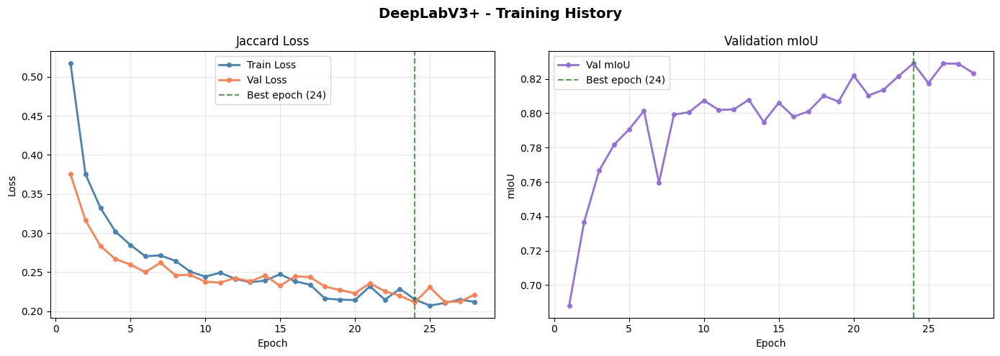

In [ ]:
# Loss Curves - DeepLabV3+

epochs_ran_d = range(1, len(train_losses_d) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('DeepLabV3+ - Training History',
             fontsize=14, fontweight='bold')

axes[0].plot(epochs_ran_d, train_losses_d,
             label='Train Loss', color='steelblue',
             linewidth=2, marker='o', markersize=4)
axes[0].plot(epochs_ran_d, val_losses_d,
             label='Val Loss', color='coral',
             linewidth=2, marker='o', markersize=4)
axes[0].set_title('Jaccard Loss', fontsize=12)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

best_epoch_d = val_losses_d.index(min(val_losses_d)) + 1
axes[0].axvline(x=best_epoch_d, color='green',
                linestyle='--', alpha=0.7,
                label=f'Best epoch ({best_epoch_d})')
axes[0].legend()

axes[1].plot(epochs_ran_d, val_ious_d,
             label='Val mIoU', color='mediumpurple',
             linewidth=2, marker='o', markersize=4)
axes[1].set_title('Validation mIoU', fontsize=12)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('mIoU')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

best_iou_epoch_d = val_ious_d.index(max(val_ious_d)) + 1
axes[1].axvline(x=best_iou_epoch_d, color='green',
                linestyle='--', alpha=0.7,
                label=f'Best epoch ({best_iou_epoch_d})')
axes[1].legend()

plt.tight_layout()
plt.savefig('/kaggle/working/deeplab_training_curves.png',
            dpi=150, bbox_inches='tight')
plt.show()

### Evaluation

In [ ]:
# Evaluation - DeepLabV3+

base_model_d = smp.DeepLabV3Plus(
    encoder_name='resnet50',
    encoder_weights=None,
    in_channels=3,
    classes=NUM_CLASSES,
).to(device)

base_model_d.load_state_dict(
    torch.load('/kaggle/working/deeplab_best.pth', map_location=device)
)
base_model_d.eval()

per_class_iou_fn_d = JaccardIndex(
    task='multiclass',
    num_classes=NUM_CLASSES,
    average='none'
).to(device)

overall_iou_fn_d = JaccardIndex(
    task='multiclass',
    num_classes=NUM_CLASSES,
    average='macro'
).to(device)

confusion_matrix_d = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long)

print('Running evaluation on test set...')
tic = time.time()

with torch.no_grad():
    pbar = tqdm(test_loader_r, desc='  Testing',
                bar_format='{l_bar}{bar:30}{r_bar}')
    for imgs, masks in pbar:
        imgs = imgs.to(device)
        masks = masks.long().to(device)

        preds = base_model_d(imgs)
        pred_classes = preds.argmax(dim=1)

        per_class_iou_fn_d.update(pred_classes, masks)
        overall_iou_fn_d.update(pred_classes, masks)

        for pred, gt in zip(pred_classes.cpu(), masks.cpu()):
            for c_true in range(NUM_CLASSES):
                for c_pred in range(NUM_CLASSES):
                    confusion_matrix_d[c_true, c_pred] += (
                        (gt == c_true) & (pred == c_pred)
                    ).sum().item()

per_class_iou_d = per_class_iou_fn_d.compute()
overall_iou_d = overall_iou_fn_d.compute().item()

mins, secs = divmod(time.time() - tic, 60)
print(f'Evaluation complete in {mins:.0f}m {secs:.2f}s')

print('  DeepLabV3+ - Test Set Results')
print(f'  {"Class":<12} {"IoU":>10}')
print('-' * 50)
for name, iou in zip(CLASS_NAMES, per_class_iou_d):
    bar = '█' * int(iou.item() * 20)
    print(f'  {name:<12} {iou.item():>8.4f}   {bar}')
print('-' * 50)
print(f'  {"mIoU":<12} {overall_iou_d:>8.4f}')
print('=' * 50)

Running evaluation on test set...


  Testing: 100%|██████████████████████████████| 201/201 [01:05<00:00,  3.08it/s]

Evaluation complete in 1m 5.23s
  DeepLabV3+ - Test Set Results
  Class               IoU
--------------------------------------------------
  Background     0.9161   ██████████████████
  Building       0.7557   ███████████████
  Woodland       0.8908   █████████████████
  Water          0.9268   ██████████████████
  Road           0.6216   ████████████
--------------------------------------------------
  mIoU           0.8222


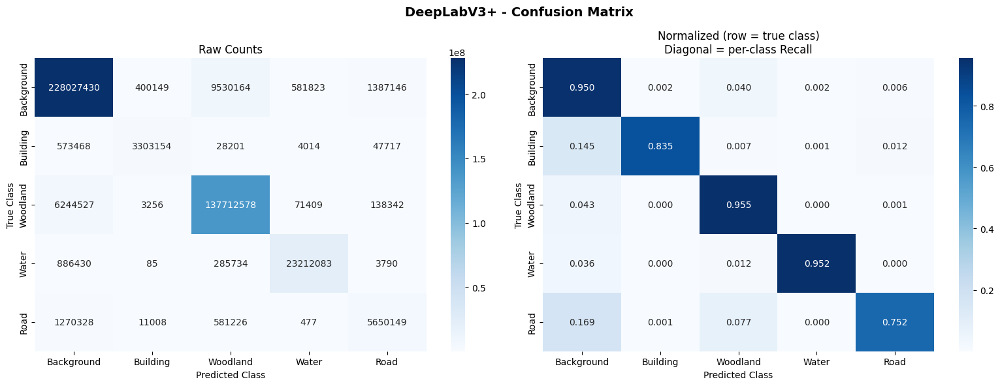

In [ ]:
# Confusion Matrix - DeepLabV3+

cm_normalized_d = confusion_matrix_d.float()
cm_normalized_d = cm_normalized_d / cm_normalized_d.sum(
    dim=1, keepdim=True).clamp(min=1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('DeepLabV3+ - Confusion Matrix',
             fontsize=14, fontweight='bold')

sns.heatmap(confusion_matrix_d.numpy(),
            annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES,
            ax=axes[0])
axes[0].set_title('Raw Counts', fontsize=12)
axes[0].set_xlabel('Predicted Class')
axes[0].set_ylabel('True Class')

sns.heatmap(cm_normalized_d.numpy(),
            annot=True, fmt='.3f', cmap='Blues',
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES,
            ax=axes[1])
axes[1].set_title('Normalized (row = true class)\nDiagonal = per-class Recall',
                  fontsize=12)
axes[1].set_xlabel('Predicted Class')
axes[1].set_ylabel('True Class')

plt.tight_layout()
plt.savefig('/kaggle/working/deeplab_confusion_matrix.png',
            dpi=150, bbox_inches='tight')
plt.show()

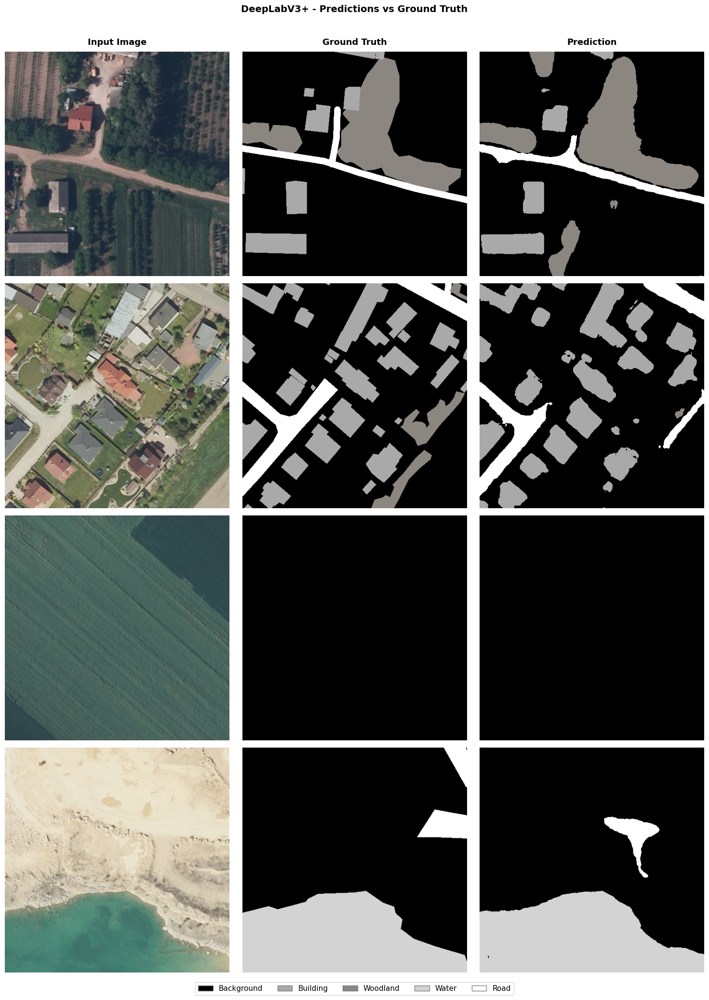

In [ ]:
# Visual Predictions - DeepLabV3+

def visualize_predictions_deeplab(model, dataset, device, n_samples=4, seed=50):
    """
    Show side-by-side: Input Image | Ground Truth | Prediction
    for DeepLabV3+. Uses ImageNet denormalization for display.
    """
    model.eval()
    np.random.seed(seed)
    indices = np.random.choice(len(dataset), n_samples, replace=False)

    fig, axes = plt.subplots(n_samples, 3, figsize=(15, 5 * n_samples))
    fig.suptitle('DeepLabV3+ - Predictions vs Ground Truth',
                 fontsize=14, fontweight='bold', y=1.01)

    col_titles = ['Input Image', 'Ground Truth', 'Prediction']
    for ax, title in zip(axes[0], col_titles):
        ax.set_title(title, fontsize=13, fontweight='bold', pad=10)

    with torch.no_grad():
        for row, idx in enumerate(indices):
            img_tensor, mask_tensor = dataset[idx]

            pred       = model(img_tensor.unsqueeze(0).to(device))
            pred_class = pred.argmax(dim=1).squeeze(0).cpu().numpy()
            mask_np    = mask_tensor.numpy()

            img_np = denormalize_imagenet(img_tensor)

            axes[row, 0].imshow(img_np)
            axes[row, 0].axis('off')

            axes[row, 1].imshow(mask_to_rgb(mask_np))
            axes[row, 1].axis('off')

            axes[row, 2].imshow(mask_to_rgb(pred_class))
            axes[row, 2].axis('off')

    legend_patches = [mpatches.Patch(
        facecolor=[c/255 for c in CLASS_COLORS_RGB[i]],
        edgecolor='gray', label=CLASS_NAMES[i])
        for i in range(NUM_CLASSES)]
    fig.legend(handles=legend_patches, loc='lower center',
               ncol=5, fontsize=11, bbox_to_anchor=(0.5, -0.02))

    plt.tight_layout()
    plt.savefig('/kaggle/working/deeplab_predictions.png',
                dpi=150, bbox_inches='tight')
    plt.show()


visualize_predictions_deeplab(base_model_d, test_dataset_r, device, n_samples=4)

## Section 7: Final Comparison & Conclusions

---


**1. Transfer learning is highly effective**

Replacing the randomly initialized encoder with a ResNet50 pretrained on ImageNet
produced the largest single improvement across all experiments. The gain is particularly
pronounced for rare classes - Building (+7.5%) and Road (+9.7%) - where the limited
number of training pixels makes learning from scratch difficult. The pretrained encoder
provides a strong initialization for detecting edges and fine structures, which is
directly useful for buildings and road boundaries in aerial imagery.

**2. ASPP improves multi-scale understanding**

DeepLabV3+'s Atrous Spatial Pyramid Pooling captures contextual information at multiple
scales simultaneously, without sacrificing spatial resolution. The largest gain is
observed on Water (+4.5%), a class whose extent varies greatly across tiles - from
small ponds to large lakes. Buildings and Roads benefit less from ASPP, as their
challenge is rarity and thin structure rather than scale variability.

**3. Road remains the hardest class across all models**

Even the best model achieves only 62.2% IoU on roads. Roads are narrow - often just
a few pixels wide - which means boundary errors contribute disproportionately to the
IoU penalty. They are also frequently occluded by overhanging trees in aerial imagery.
This is a fundamental characteristic of the dataset, confirmed in the original paper,
and not a limitation specific to our implementation.

In [ ]:
# Results Summary

# Store all results
results = {
    'Vanilla U-Net': {
        'per_class': [0.8729, 0.6753, 0.8488, 0.7783, 0.4969],
        'miou': 0.7344,
        'color': 'steelblue'
    },
    'U-Net + ResNet50': {
        'per_class': [0.9049, 0.7506, 0.8774, 0.8812, 0.5941],
        'miou': 0.8016,
        'color': 'coral'
    },
    'DeepLabV3+': {
        'per_class': [per_class_iou_d[i].item() for i in range(NUM_CLASSES)],
        'miou': overall_iou_d,
        'color': 'mediumpurple'
    }
}

# Print comparison table
print('=' * 75)
print('  FINAL COMPARISON - All Experiments')
print('=' * 75)
print(f'  {"Class":<14}', end='')
for model_name in results.keys():
    print(f'  {model_name:>17}', end='')
print()
print('-' * 75)

for i, class_name in enumerate(CLASS_NAMES):
    print(f'  {class_name:<14}', end='')
    for model_data in results.values():
        iou = model_data['per_class'][i]
        print(f'  {iou:>17.4f}', end='')
    print()

print('-' * 75)
print(f'  {"mIoU":<14}', end='')
for model_data in results.values():
    print(f'  {model_data["miou"]:>17.4f}', end='')

  FINAL COMPARISON - All Experiments
  Class               Vanilla U-Net   U-Net + ResNet50         DeepLabV3+
---------------------------------------------------------------------------
  Background                 0.8729             0.9049             0.9161
  Building                   0.6753             0.7506             0.7557
  Woodland                   0.8488             0.8774             0.8908
  Water                      0.7783             0.8812             0.9268
  Road                       0.4969             0.5941             0.6216
---------------------------------------------------------------------------
  mIoU                       0.7344             0.8016             0.8222